# 01 · Análisis espacial, métricas de correlación y texto como datos

Qué hace. Describe en el espacio las variables brutas de las fuentes (Kaggle, Google Earth Engine y OpenStreetMap) y
transforma el título y la descripción de cada aviso en variables de texto. Las secciones 1 a 8 son descriptivas: mapas en
la coordenada exacta, correlaciones con el precio, autocorrelación espacial y precisión de las coordenadas. Las secciones 9
y 10 construyen la base de texto que usa el modelo: limpieza, corrección ortográfica con BETO, diccionarios con negación,
cantidades extraídas, matriz documento término, TF-IDF, LSA, tópicos LDA y embeddings de BETO.

Cómo. Con `RECALCULAR = False` (valor por defecto) el cuaderno no escribe en `stores/`: recalcula lo descriptivo y la base
de texto en CPU y compara cada resultado con el archivo guardado (imprime si coincide). Los dos pasos que usan BETO en GPU
no se vuelven a correr: la corrección ortográfica aplica las correcciones aceptadas guardadas en la auditoría y los
embeddings se leen de `stores/texto/beto_embeddings.npy`. Con `RECALCULAR = True` todo se recalcula (BETO en GPU si hay
una) y se escribe solo en `stores/recalculo/`. Los mapas no llevan mapa base, porque descargarlo requiere internet;
`USAR_MAPA_BASE = True` lo agrega. Las figuras de `views/01_*.png` ya existentes (con mapa base) no se sobrescriben.

Para qué. Responde la Etapa 1 del enunciado (distribución de precios, faltantes, relaciones y en qué se diferencia
Chapinero) y deja listas las variables de texto del modelo final (cuaderno 02).

Conceptos de clase que usa:

| Concepto | Dónde se enseña | Sección |
|---|---|---|
| Datos espaciales, CRS y EPSG:9377 | Lecture 14, diap. 5 a 11; lecturas Datos espaciales y Fundamentos teóricos | 0 a 3 |
| Dependencia espacial (Tobler), autocorrelación, I de Moran y LISA | Lecture 14, diap. 13 y 14 | 7 |
| Alcance de la dependencia como guía para bloques y buffer | Lecture 14, diap. 26 a 29 | 7.2 |
| Limpieza, stopwords, stemming Snowball, n-gramas, DTM | Lecture 15, diap. 11 a 23; lectura Texto como datos (k) | 9.1 a 9.5 |
| Diccionarios con negación (función `detectar_caracteristica`) | Lectura Texto como datos (k) | 9.3 |
| TF-IDF | Lecture 15, diap. 18 | 9.6 |
| LSA como PCA y LDA | Lecture 15, diap. 37 a 63; Gentzkow, Kelly y Taddy (2019) | 9.7 |
| Embeddings contextuales y BETO | Lecture 15, diap. 91 a 94; Ash y Hansen (2023), pp. 666 a 668 | 10 |
| Autoatención | Vaswani y otros (2017) | 10.2 |

Orden de ejecución: después de `00`. Tiempo con `RECALCULAR = False`: unos 6 minutos en CPU (lo más lento es elegir el
número de tópicos del LDA). Con `RECALCULAR = True` y GPU, unos 10 minutos.

## 0. Configuración y datos

In [1]:
# RECALCULAR = False: no escribe en stores/; compara cada resultado con el archivo guardado y no usa BETO en GPU.
# RECALCULAR = True: recalcula todo y escribe solo en stores/recalculo/ (y las figuras en stores/recalculo/views/).
RECALCULAR = False
USAR_MAPA_BASE = False      # True: agrega el mapa base de Esri a los mapas (requiere internet)

import io
import os
import warnings
warnings.filterwarnings("ignore")
if not RECALCULAR:
    os.environ["HF_HUB_OFFLINE"] = "1"     # el tokenizador de BETO se lee de la copia local

from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx
from scipy.spatial import cKDTree
from scipy.stats import spearmanr, pearsonr

RAIZ = Path("..")
DATA, STORES, VIEWS = RAIZ / "Kaggle", RAIZ / "stores", RAIZ / "views"
RECALCULO = STORES / "recalculo"
CRS_GEO, CRS_M = "EPSG:4326", "EPSG:9377"          # 9377: MAGNA-SIRGAS Origen Nacional (metros)
VECINAS = ["Usaquén", "Barrios Unidos", "Teusaquillo", "Santa Fe"]
COLOR_TRAIN, COLOR_TEST = "#4C72B0", "#C44E52"
SEMILLA = 2026
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


def guardar(fig, nombre):
    """Figuras: con RECALCULAR van a stores/recalculo/views/; si no, solo se escriben si no existen en views/
    (las existentes tienen mapa base y no se sobrescriben)."""
    if RECALCULAR:
        (RECALCULO / "views").mkdir(parents=True, exist_ok=True)
        fig.savefig(RECALCULO / "views" / f"01_{nombre}.png")
    elif not (VIEWS / f"01_{nombre}.png").exists():
        fig.savefig(VIEWS / f"01_{nombre}.png")


def _comparar(nuevo, guardado, nombre):
    """Compara dos tablas (texto CSV): exacto; si no, contenido sin importar el orden de filas; si no, por columna."""
    norm = lambda s: s.replace(chr(13) + chr(10), chr(10))     # fin de línea de Windows
    if norm(nuevo) == norm(guardado):
        print(f"Coincide exactamente con {nombre}")
        return
    a, b = (pd.read_csv(io.StringIO(t), dtype=str, keep_default_na=False) for t in (nuevo, guardado))
    if a.shape != b.shape or list(a.columns) != list(b.columns):
        print(f"Difiere de {nombre}: forma {a.shape} frente a {b.shape}")
        return
    orden = lambda d: d.sort_values(list(d.columns)).reset_index(drop=True)
    if orden(a).equals(orden(b)):
        print(f"Coincide con {nombre} (mismas filas; cambia el orden entre empates)")
        return
    distintas = [c for c in a.columns if not (a[c].values == b[c].values).all()]
    print(f"Difiere de {nombre} en las columnas {distintas}")


def guardar_tabla(df, nombre, carpeta=None, **kw):
    """Tablas: con RECALCULAR se escriben en stores/recalculo/; si no, se comparan con el archivo guardado."""
    carpeta = carpeta if carpeta is not None else STORES
    nuevo = df.to_csv(**kw)
    if RECALCULAR:
        destino = RECALCULO / carpeta.relative_to(STORES)
        destino.mkdir(parents=True, exist_ok=True)
        (destino / nombre).write_text(nuevo, encoding="utf-8")
    else:
        _comparar(nuevo, (carpeta / nombre).read_text(encoding="utf-8"), f"{carpeta.name}/{nombre}")


def guardar_parquet(df, nombre, carpeta):
    """Bases en parquet: con RECALCULAR se escriben en stores/recalculo/; si no, se comparan columna por columna."""
    if RECALCULAR:
        destino = RECALCULO / carpeta.relative_to(STORES)
        destino.mkdir(parents=True, exist_ok=True)
        df.to_parquet(destino / nombre, index=False)
        return
    ref = pd.read_parquet(carpeta / nombre)
    df = df.reset_index(drop=True)
    if list(df.columns) != list(ref.columns) or len(df) != len(ref):
        print(f"Difiere de {nombre}: columnas o filas distintas")
        return
    distintas = {}
    for c in df.columns:
        if df[c].dtype.kind in "fi":
            d = np.nanmax(np.abs(df[c].to_numpy(float) - ref[c].to_numpy(float))) if len(df) else 0
            if not (d < 1e-6 and (df[c].isna() == ref[c].isna()).all()):
                distintas[c] = d
        elif not (df[c].astype(str).values == ref[c].astype(str).values).all():
            distintas[c] = "texto distinto"
    print(f"Coincide con {nombre} ({df.shape[1]} columnas)" if not distintas
          else f"{nombre}: {len(distintas)} columnas difieren; ejemplos {dict(list(distintas.items())[:4])}")


# ---------------------------------------------------------------------------------------------------------------
# Etiquetas en español para tablas y gráficos (los nombres de columna originales se mantienen en el código)
# ---------------------------------------------------------------------------------------------------------------
ETIQUETAS = {
    # Kaggle
    "price": "Precio (COP)", "precio_mill": "Precio (millones)", "log_precio": "Logaritmo del precio",
    "precio_m2_mill": "Precio por m² (millones)", "surface_covered": "Área cubierta (m²)", "surface_total": "Área total (m²)",
    "rooms": "Ambientes", "bedrooms": "Alcobas", "bathrooms": "Baños", "es_apartamento": "Es apartamento (0/1)",
    "year": "Año de publicación", "month": "Mes de publicación",
    # Google Earth Engine
    "elevacion_m": "Elevación (m)", "pendiente_grados": "Pendiente (°)", "ndvi_200m": "Vegetación NDVI (200 m)",
    "luces_nocturnas": "Luces nocturnas", "altura_construida_m": "Altura construida (m)",
    "poblacion_100m": "Población (celda de 100 m)",
}
CATEGORIAS = {"bar_cafe": "Bares y cafés", "centro_comercial": "Centros comerciales", "colegio": "Colegios",
              "estacion": "Estaciones de transporte", "hospital": "Hospitales y clínicas", "paradero": "Paraderos de bus",
              "parque": "Parques", "policia": "Policía", "restaurante": "Restaurantes", "supermercado": "Supermercados",
              "universidad": "Universidades", "via_principal": "Vías principales"}
for k, v in CATEGORIAS.items():
    ETIQUETAS[f"osm_{k}"] = f"OSM · {v} (número en la celda)"
for k in ["elevacion_m", "pendiente_grados", "ndvi_200m", "luces_nocturnas", "altura_construida_m", "poblacion_100m"]:
    ETIQUETAS[f"gee_{k}"] = f"GEE · {ETIQUETAS[k]} (promedio en la celda)"
MUESTRA = {"train": "Entrenamiento", "test": "Prueba"}


def es(nombre):
    """Etiqueta en español de una variable (si no está en el diccionario, se devuelve igual)."""
    return ETIQUETAS.get(nombre, nombre)



# Kaggle + Earth Engine (unión por coordenadas exactas)
kag = pd.concat([pd.read_csv(DATA / "train.csv").assign(muestra="train"),
                 pd.read_csv(DATA / "test.csv").assign(muestra="test")], ignore_index=True)
gee = pd.read_parquet(STORES / "gee_features.parquet")
GEE = [c for c in gee.columns if c not in ("lat", "lon")]
df = kag.merge(gee, on=["lat", "lon"], how="left")
assert len(df) == len(kag) and df[GEE].notna().all().all()

# Variables numéricas derivadas solo para describir (no se guardan)
df["precio_mill"] = df["price"] / 1e6
df["log_precio"] = np.log(df["price"])
area = df["surface_covered"].fillna(df["surface_total"])
df["precio_m2_mill"] = (df["precio_mill"] / area).where(area.between(15, 1000))
df["es_apartamento"] = (df["property_type"] == "Apartamento").astype(int)

# Geometría, localidad y zona
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs=CRS_GEO).to_crs(CRS_M)
localidades = gpd.read_file(STORES / "localidades_bogota.geojson").to_crs(CRS_M)
gdf = gdf.sjoin(localidades[["localidad", "geometry"]], how="left", predicate="within").drop(columns="index_right")
gdf = gdf[~gdf.index.duplicated()]
gdf["localidad"] = gdf["localidad"].fillna("Fuera de límites")
gdf["zona"] = np.select([gdf["localidad"] == "Chapinero", gdf["localidad"].isin(VECINAS)], ["Chapinero", "Vecinas"], "Resto")
gdf["x"], gdf["y"] = gdf.geometry.x, gdf.geometry.y
chap = localidades[localidades["localidad"] == "Chapinero"]
tr = gdf[gdf["muestra"] == "train"]

osm = gpd.read_parquet(STORES / "osm" / "amenidades_osm.parquet").to_crs(CRS_M)
osm["geometry"] = osm.geometry.representative_point()            # un punto por objeto (centro de áreas y líneas)

EXTENT = gdf.total_bounds + np.array([-1000, -1000, 1000, 1000])
print(f"Avisos: {len(gdf):,} (entrenamiento {len(tr):,}) | objetos OSM: {len(osm):,} | capas GEE: {[es(g) for g in GEE]}")


def mapa_base(ax, extent=EXTENT, contorno=True):
    """Límites de localidades, contorno de Chapinero y, si USAR_MAPA_BASE, mapa base de Esri."""
    localidades.boundary.plot(ax=ax, color="black", lw=0.3, alpha=0.5)
    if contorno:
        chap.boundary.plot(ax=ax, color="black", lw=1.6)
    ax.set_xlim(extent[0], extent[2]); ax.set_ylim(extent[1], extent[3])
    if USAR_MAPA_BASE:
        try:
            cx.add_basemap(ax, crs=CRS_M, source=cx.providers.Esri.WorldGrayCanvas, attribution_size=4)
        except Exception:
            pass
    ax.set_axis_off()


def puntomapa(ax, d, var, titulo, cmap="viridis", robusto=True, s=2.5):
    """Mapa en coordenadas exactas: un punto por coordenada; si varios avisos comparten la coordenada, el punto
    toma el promedio de esos avisos. Orden de dibujo aleatorio para no ocultar sistemáticamente valores altos o bajos."""
    u = d.groupby(["x", "y"], as_index=False).agg(valor=(var, "mean"), n=(var, "size")).dropna(subset=["valor"])
    u = u.sample(frac=1, random_state=SEMILLA)
    kw = dict(vmin=u["valor"].quantile(.02), vmax=u["valor"].quantile(.98)) if robusto else {}
    sc = ax.scatter(u["x"], u["y"], c=u["valor"], s=s, cmap=cmap, linewidths=0, **kw)
    mapa_base(ax)
    plt.colorbar(sc, ax=ax, shrink=0.55)
    ax.set_title(f"{titulo}\n({len(u):,} coordenadas exactas)", fontsize=10)
    return u


Avisos: 48,930 (entrenamiento 38,644) | objetos OSM: 23,623 | capas GEE: ['Elevación (m)', 'Pendiente (°)', 'Vegetación NDVI (200 m)', 'Luces nocturnas', 'Altura construida (m)', 'Población (celda de 100 m)']


## 1. Mapas de las variables de Kaggle (coordenadas exactas)

Cada punto es una coordenada exacta $\ell = (\text{lat}, \text{lon})$ de los datos. Como el 67 % de los avisos comparte
coordenadas con otro (hasta 144 avisos en un mismo punto), dibujar aviso por aviso haría que los puntos se taparan y el mapa
dependiera del orden de dibujo. Por eso cada coordenada se dibuja una vez, con el promedio de los $n_\ell$ avisos que
tiene (si $n_\ell = 1$, es el valor del propio aviso):

$$\bar{x}_\ell = \frac{1}{n_\ell} \sum_{i \,:\, (\text{lat}_i, \text{lon}_i) = \ell} x_i$$

Los puntos se dibujan en orden aleatorio y la escala de color se recorta entre los percentiles 2 y 98 (los valores imposibles
de los datos brutos, como áreas de 108.800 m², no deben dominar la escala). Contorno negro grueso: Chapinero. El precio solo se
observa en entrenamiento; las demás variables incluyen entrenamiento y prueba.

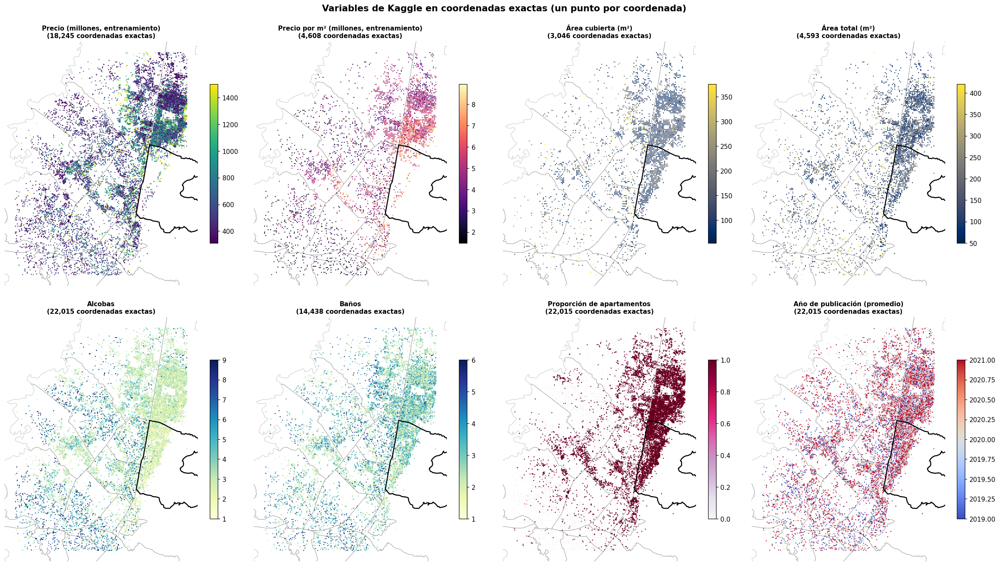

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(22, 13))
paneles = [
    (tr, "precio_mill", "Precio (millones, entrenamiento)", "viridis", True),
    (tr, "precio_m2_mill", "Precio por m² (millones, entrenamiento)", "magma", True),
    (gdf, "surface_covered", "Área cubierta (m²)", "cividis", True),
    (gdf, "surface_total", "Área total (m²)", "cividis", True),
    (gdf, "bedrooms", "Alcobas", "YlGnBu", True),
    (gdf, "bathrooms", "Baños", "YlGnBu", True),
    (gdf, "es_apartamento", "Proporción de apartamentos", "PuRd", False),
    (gdf, "year", "Año de publicación (promedio)", "coolwarm", False),
]
for ax, (d, v, t, cm, rob) in zip(axes.ravel(), paneles):
    puntomapa(ax, d, v, t, cm, robusto=rob)
fig.suptitle("Variables de Kaggle en coordenadas exactas (un punto por coordenada)", fontweight="bold", fontsize=14)
fig.tight_layout()
guardar(fig, "mapas_kaggle")
plt.show()

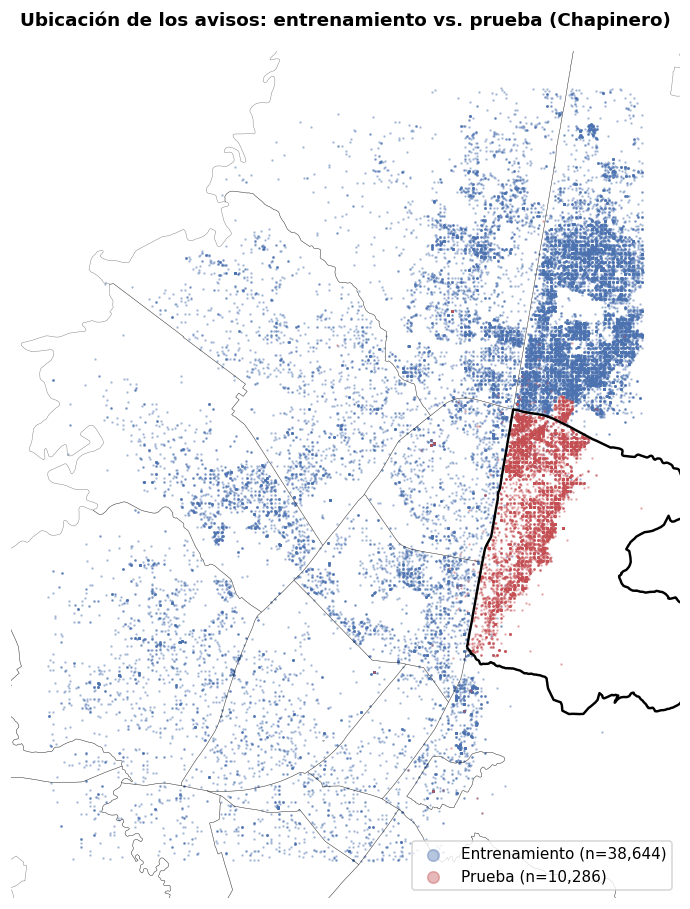

In [3]:
fig, ax = plt.subplots(figsize=(8, 10))
tr.plot(ax=ax, markersize=0.4, color=COLOR_TRAIN, alpha=0.4, label=f"Entrenamiento (n={len(tr):,})")
gdf[gdf["muestra"] == "test"].plot(ax=ax, markersize=0.4, color=COLOR_TEST, alpha=0.4,
                                   label=f"Prueba (n={(gdf['muestra'] == 'test').sum():,})")
mapa_base(ax)
ax.legend(markerscale=12, loc="lower right", frameon=True)
ax.set_title("Ubicación de los avisos: entrenamiento vs. prueba (Chapinero)")
guardar(fig, "mapa_train_test")
plt.show()

## 2. Mapas de las capas de Google Earth Engine (coordenadas exactas)

Cada capa se extrajo en la coordenada exacta de cada aviso, así que el valor es único por coordenada:
$x_\ell = G^{(m)}(\text{lat}_\ell, \text{lon}_\ell)$, el valor del píxel de la capa $m$ que contiene la ubicación $\ell$.

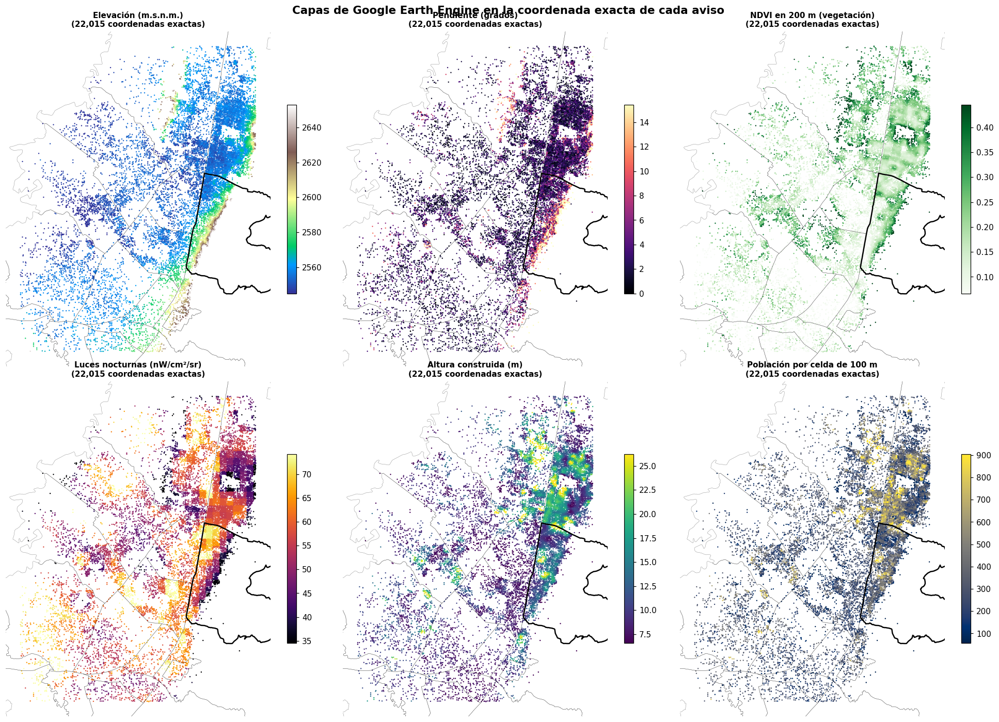

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 13))
cmaps = ["terrain", "magma", "Greens", "inferno", "viridis", "cividis"]
titulos = {"elevacion_m": "Elevación (m.s.n.m.)", "pendiente_grados": "Pendiente (grados)",
           "ndvi_200m": "NDVI en 200 m (vegetación)", "luces_nocturnas": "Luces nocturnas (nW/cm²/sr)",
           "altura_construida_m": "Altura construida (m)", "poblacion_100m": "Población por celda de 100 m"}
for ax, v, cm in zip(axes.ravel(), GEE, cmaps):
    puntomapa(ax, gdf, v, titulos[v], cm)
fig.suptitle("Capas de Google Earth Engine en la coordenada exacta de cada aviso", fontweight="bold", fontsize=14)
fig.tight_layout()
guardar(fig, "mapas_gee")
plt.show()

## 3. Mapas de OpenStreetMap (ubicación exacta de cada objeto)

Cada objeto se dibuja en su ubicación exacta: los puntos (nodos) en su coordenada, los parques con su polígono completo, las
vías principales con su trazado y las demás áreas (por ejemplo, colegios o centros comerciales mapeados como polígono) en un
punto interior del polígono.

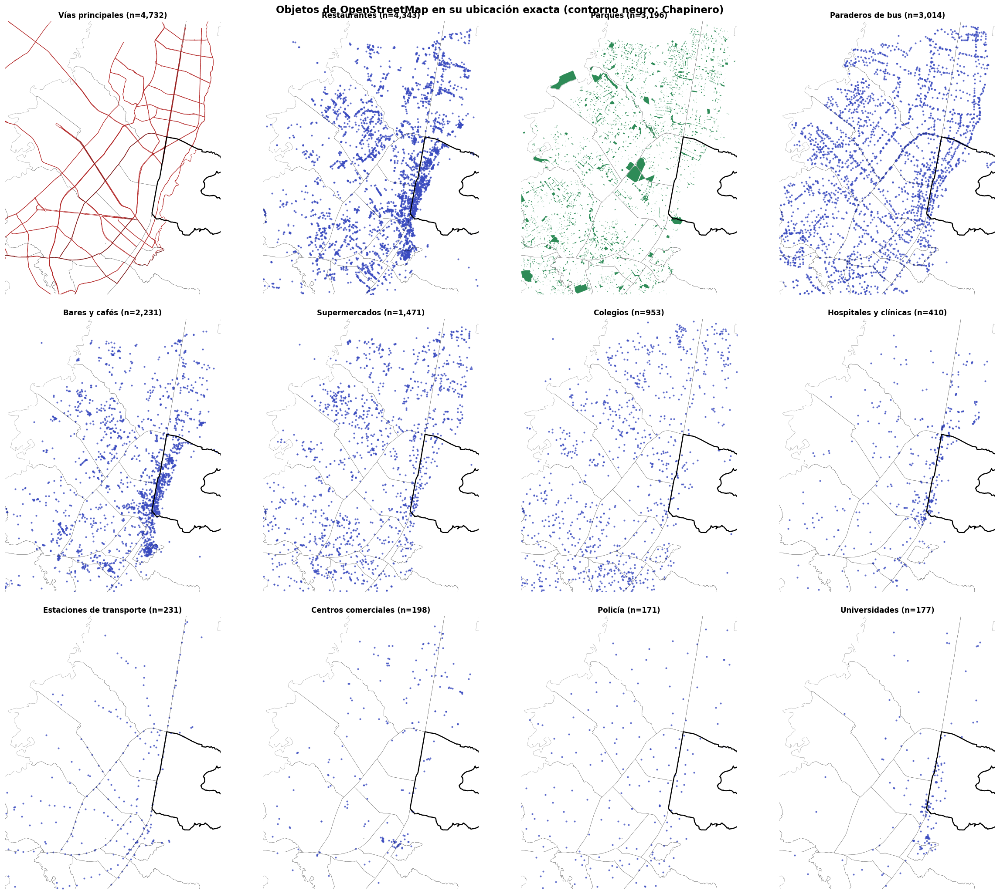

In [5]:
osm_geo = gpd.read_parquet(STORES / "osm" / "amenidades_osm.parquet").to_crs(CRS_M)   # geometrías originales
cats = osm_geo["categoria"].value_counts().index.tolist()
fig, axes = plt.subplots(3, 4, figsize=(22, 19))
for ax, cat in zip(axes.ravel(), cats):
    g = osm_geo[osm_geo["categoria"] == cat].cx[EXTENT[0]:EXTENT[2], EXTENT[1]:EXTENT[3]]
    if cat == "parque":
        g[g.geom_type.isin(["Polygon", "MultiPolygon"])].plot(ax=ax, color="#2E8B57", lw=0)
        pts_ = g[~g.geom_type.isin(["Polygon", "MultiPolygon"])]
        ax.scatter(pts_.geometry.x, pts_.geometry.y, s=3, color="#2E8B57")
    elif cat == "via_principal":
        g.plot(ax=ax, color="#B22222", lw=0.6)
    else:
        p = g.geometry.representative_point()
        ax.scatter(p.x, p.y, s=3, color="#3B4CC0", alpha=0.7)
    mapa_base(ax)
    ax.set_title(f"{CATEGORIAS[cat]} (n={len(g):,})", fontsize=11)
fig.suptitle("Objetos de OpenStreetMap en su ubicación exacta (contorno negro: Chapinero)", fontweight="bold", fontsize=15)
fig.tight_layout()
guardar(fig, "mapas_osm")
plt.show()

## 4. Correlación de cada variable con el precio (aviso por aviso, entrenamiento)

Se reporta contra tres medidas del precio, para el aviso $i$ con precio $P_i$ (COP) y área $A_i$ (m²):

$$\text{precio}_i = \frac{P_i}{10^6}, \qquad \text{log-precio}_i = \ln P_i, \qquad
\text{precio/m}^2_i = \frac{P_i / 10^6}{A_i}, \quad A_i = \begin{cases} \text{surface\_covered}_i & \text{si existe} \\
\text{surface\_total}_i & \text{si no} \end{cases}, \quad 15 \le A_i \le 1000$$

Coeficiente de correlación de Pearson (relación lineal) entre una variable $x$ y el precio $y$, con los $n$ avisos que
tienen ambos datos:

$$r_{xy} = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2}\,
\sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}, \qquad -1 \le r_{xy} \le 1$$

Coeficiente de correlación de Spearman (relación monótona): es la correlación de Pearson calculada sobre los rangos
$R(x_i)$ y $R(y_i)$, por lo que es robusta a valores extremos y a relaciones no lineales pero crecientes o decrecientes:

$$\rho_{xy} = \frac{\sum_{i=1}^{n} \big(R(x_i) - \bar{R}_x\big)\big(R(y_i) - \bar{R}_y\big)}
{\sqrt{\sum_{i=1}^{n} \big(R(x_i) - \bar{R}_x\big)^2}\,\sqrt{\sum_{i=1}^{n} \big(R(y_i) - \bar{R}_y\big)^2}}
\;\;\overset{\text{sin empates}}{=}\;\; 1 - \frac{6 \sum_{i=1}^{n} d_i^2}{n(n^2 - 1)}, \quad d_i = R(x_i) - R(y_i)$$

`n` = avisos con dato en ambas variables (las superficies, los ambientes (`rooms`) y los baños (`bathrooms`) tienen faltantes).

In [6]:
VARS = ["surface_total", "surface_covered", "rooms", "bedrooms", "bathrooms", "es_apartamento", "year"] + GEE
OBJETIVOS = {"precio_mill": "precio", "log_precio": "log-precio", "precio_m2_mill": "precio/m²"}


def correlaciones(d, x, y):
    ok = d[[x, y]].dropna()
    if len(ok) < 10 or ok[x].nunique() < 2:
        return np.nan, np.nan, len(ok)
    return pearsonr(ok[x], ok[y])[0], spearmanr(ok[x], ok[y])[0], len(ok)


filas = []
for v in VARS:
    fila = {"variable": v}
    for y, nombre in OBJETIVOS.items():
        p, s, n = correlaciones(tr, v, y)
        fila[f"Pearson {nombre}"], fila[f"Spearman {nombre}"] = p, s
        if y == "precio_mill":
            fila["n"] = n
    filas.append(fila)
corr_precio = pd.DataFrame(filas).set_index("variable").sort_values("Spearman precio", key=np.abs, ascending=False)
guardar_tabla(corr_precio.assign(nombre=corr_precio.index.map(es)), "01_correlaciones_precio.csv")
corr_precio.rename(index=es).rename_axis("variable")

Coincide exactamente con stores/01_correlaciones_precio.csv


,Pearson precio,Spearman precio,n,Pearson log-precio,Spearman log-precio,Pearson precio/m²,Spearman precio/m²
variable,,,,,,,
Área cubierta (m²),0.672,0.788,8565,0.668,0.788,-0.372,-0.373
Área total (m²),0.181,0.696,7854,0.176,0.696,-0.370,-0.461
Baños,0.555,0.616,28573,0.569,0.616,-0.216,-0.212
Ambientes,0.269,0.385,20384,0.284,0.385,-0.440,-0.534
Alcobas,0.224,0.338,38644,0.236,0.338,-0.503,-0.581
Es apartamento (0/1),-0.183,-0.186,38644,-0.187,-0.186,0.466,0.539
Vegetación NDVI (200 m),0.097,0.066,38644,0.085,0.066,0.051,0.046
Pendiente (°),0.151,0.055,38644,0.134,0.055,0.167,0.171
Elevación (m),0.109,0.055,38644,0.094,0.055,0.132,0.104


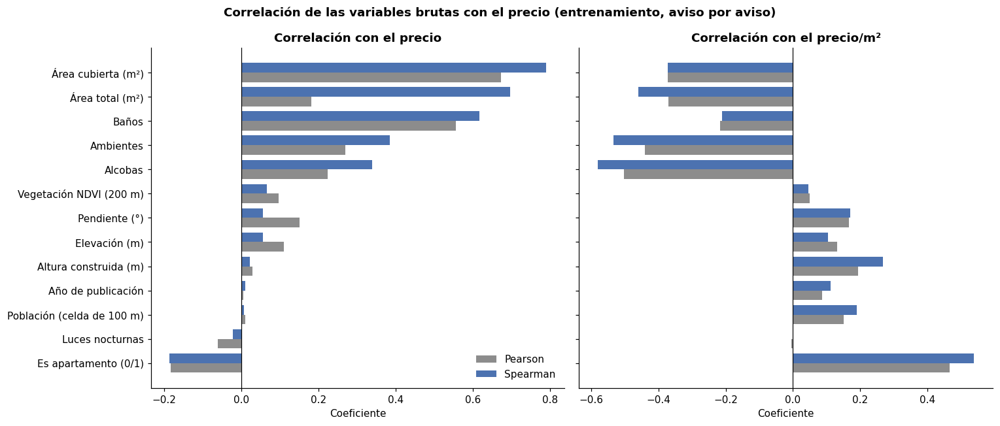

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
orden = corr_precio.sort_values("Spearman precio").index
for ax, nombre in zip(axes, ["precio", "precio/m²"]):
    d = corr_precio.loc[orden]
    pos = np.arange(len(d))
    ax.barh(pos - 0.2, d[f"Pearson {nombre}"], 0.4, label="Pearson", color="#8C8C8C")
    ax.barh(pos + 0.2, d[f"Spearman {nombre}"], 0.4, label="Spearman", color="#4C72B0")
    ax.set_yticks(pos, [es(v) for v in d.index])
    ax.axvline(0, color="black", lw=0.8)
    ax.set(title=f"Correlación con el {nombre}", xlabel="Coeficiente")
axes[0].legend(frameon=False)
fig.suptitle("Correlación de las variables brutas con el precio (entrenamiento, aviso por aviso)", fontweight="bold")
fig.tight_layout()
guardar(fig, "correlacion_precio")
plt.show()

### Matriz de correlación entre todas las variables (Spearman, entrenamiento)

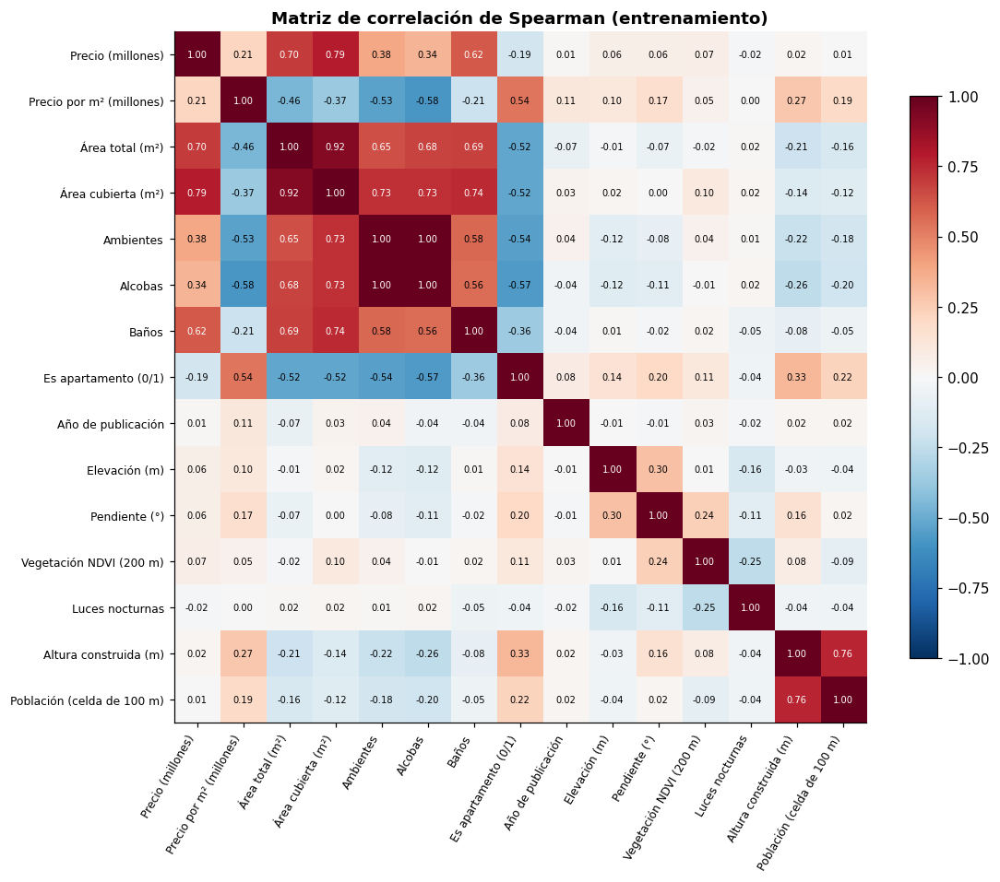

In [8]:
M = tr[["precio_mill", "precio_m2_mill"] + VARS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(M)), [es(v) for v in M.columns], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(M)), [es(v) for v in M.index], fontsize=8)
for i in range(len(M)):
    for j in range(len(M)):
        if np.isfinite(M.iloc[i, j]):
            ax.text(j, i, f"{M.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(M.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Matriz de correlación de Spearman (entrenamiento)")
guardar(fig, "matriz_correlacion")
plt.show()

## 5. ¿La relación con el precio es la misma en Chapinero? (Spearman por zona)

Chapinero tiene solo 307 avisos con precio en entrenamiento, así que sus coeficientes son más ruidosos.

In [9]:
por_zona = {}
for z in ["Chapinero", "Vecinas", "Resto"]:
    d = tr[tr["zona"] == z]
    por_zona[(z, "precio")] = {v: correlaciones(d, v, "precio_mill")[1] for v in VARS}
    por_zona[(z, "precio/m²")] = {v: correlaciones(d, v, "precio_m2_mill")[1] for v in VARS}
    por_zona[(z, "n")] = {v: correlaciones(d, v, "precio_mill")[2] for v in VARS}
corr_zona = pd.DataFrame(por_zona)
guardar_tabla(corr_zona, "01_correlaciones_por_zona.csv")
corr_zona.loc[corr_precio.index].rename(index=es).rename_axis("variable")

Coincide exactamente con stores/01_correlaciones_por_zona.csv


Chapinero                Vecinas                   \
                              precio precio/m²    n  precio precio/m²      n   
variable                                                                       
Área cubierta (m²)             0.892    -0.209  150   0.841    -0.290   6175   
Área total (m²)                0.859    -0.355  215   0.823    -0.351   4737   
Baños                          0.704    -0.168  289   0.669    -0.140  18446   
Ambientes                      0.572    -0.300  176   0.484    -0.445  15026   
Alcobas                        0.548    -0.389  307   0.476    -0.458  26167   
Es apartamento (0/1)          -0.086    -0.009  307  -0.242     0.359  26167   
Vegetación NDVI (200 m)        0.275    -0.004  307   0.094    -0.044  26167   
Pendiente (°)                  0.061    -0.028  307   0.058     0.091  26167   
Elevación (m)                  0.048    -0.086  307  -0.034    -0.041  26167   
Altura construida (m)         -0.169    -0.226  307   0.042     0.157  26167   
Luces nocturnas               -0.122     0.069  307   0.071     0.080  26167   
Año de publicación             0.062    -0.065  307   0.012     0.094  26167   
Población (celda de 100 m)    -0.114    -0.072  307   0.013     0.128  26167   

                            Resto                   
                           precio precio/m²      n  
variable                                            
Área cubierta (m²)          0.732    -0.569   2240  
Área total (m²)             0.604    -0.555   2902  
Baños                       0.567    -0.336   9838  
Ambientes                   0.340    -0.626   5182  
Alcobas                     0.280    -0.656  12170  
Es apartamento (0/1)       -0.293     0.656  12170  
Vegetación NDVI (200 m)     0.041     0.328  12170  
Pendiente (°)               0.009     0.203  12170  
Elevación (m)               0.119    -0.092  12170  
Altura construida (m)      -0.099     0.380  12170  
Luces nocturnas            -0.175    -0.056  12170  
Año de publicación         -0.012     0.114  12170  
Población (celda de 100 m) -0.079     0.144  12170

## 6. Correlación en celdas de 500 m: precio vs. amenidades de OSM y capas de GEE

Las amenidades de OSM son objetos, no atributos del aviso. Para relacionarlas con el precio sin construir variables a nivel
de aviso, se agrega todo a una grilla de celdas de 500 m × 500 m. Cada punto con coordenadas métricas $(x, y)$
(EPSG:9377) pertenece a la celda

$$c(x, y) = \left(\left\lfloor \frac{x}{500} \right\rfloor,\; \left\lfloor \frac{y}{500} \right\rfloor\right)$$

y para cada celda $c$ con $n_c \ge 5$ avisos de entrenamiento se calcula:

$$\tilde{P}_c = \operatorname{mediana}\{\text{precio}_i : i \in c\}, \qquad
N^{(k)}_c = \#\{\text{objetos OSM de la categoría } k \text{ en } c\}, \qquad
\bar{G}^{(m)}_c = \frac{1}{|c|} \sum_{i \in c} G^{(m)}_i$$

donde $G^{(m)}$ es la capa $m$ de Earth Engine. Luego se calcula la correlación de Spearman $\rho$ entre $\tilde{P}_c$ (o la
mediana del precio por m²) y cada $N^{(k)}_c$ o $\bar{G}^{(m)}_c$ a través de las celdas.

In [10]:
TAM = 500
def celda(x, y):
    return (np.floor(x / TAM).astype(int)).astype(str) + "_" + (np.floor(y / TAM).astype(int)).astype(str)

tr_c = tr.assign(celda=celda(tr["x"].values, tr["y"].values))
osm_c = osm.assign(celda=celda(osm.geometry.x.values, osm.geometry.y.values))
gdf_c = gdf.assign(celda=celda(gdf["x"].values, gdf["y"].values))

agg = tr_c.groupby("celda").agg(avisos=("price", "size"), precio_mediano=("precio_mill", "median"),
                                precio_m2_mediano=("precio_m2_mill", "median"))
agg = agg[agg["avisos"] >= 5]
agg = agg.join(osm_c.groupby(["celda", "categoria"]).size().unstack(fill_value=0).add_prefix("osm_"), how="left").fillna(0)
agg = agg.join(gdf_c.groupby("celda")[GEE].mean().add_prefix("gee_"), how="left")
print(f"Celdas de 500 m con al menos 5 avisos de entrenamiento: {len(agg):,}")

VARS_CELDA = [c for c in agg.columns if c.startswith(("osm_", "gee_"))]
corr_celda = pd.DataFrame({
    "Spearman precio mediano": [spearmanr(agg[v], agg["precio_mediano"])[0] for v in VARS_CELDA],
    "Spearman precio/m² mediano": [spearmanr(agg[v], agg["precio_m2_mediano"], nan_policy="omit")[0] for v in VARS_CELDA],
    "Pearson precio/m² mediano": [agg[[v, "precio_m2_mediano"]].dropna().corr().iloc[0, 1] for v in VARS_CELDA],
}, index=VARS_CELDA).sort_values("Spearman precio/m² mediano", key=np.abs, ascending=False)
guardar_tabla(corr_celda.assign(nombre=corr_celda.index.map(es)), "01_correlaciones_celdas_500m.csv")
corr_celda.rename(index=es).rename_axis("variable")

Celdas de 500 m con al menos 5 avisos de entrenamiento: 728
Coincide exactamente con stores/01_correlaciones_celdas_500m.csv


,Spearman precio mediano,Spearman precio/m² mediano,Pearson precio/m² mediano
variable,,,
GEE · Pendiente (°) (promedio en la celda),0.103,0.378,0.301
GEE · Altura construida (m) (promedio en la celda),-0.048,0.352,0.280
GEE · Vegetación NDVI (200 m) (promedio en la celda),0.037,0.281,0.210
OSM · Colegios (número en la celda),-0.059,-0.271,-0.226
OSM · Vías principales (número en la celda),0.092,0.188,0.188
GEE · Elevación (m) (promedio en la celda),0.215,0.174,0.234
GEE · Población (celda de 100 m) (promedio en la celda),-0.087,0.166,0.172
OSM · Universidades (número en la celda),0.080,0.150,0.096
OSM · Hospitales y clínicas (número en la celda),0.091,0.126,0.169


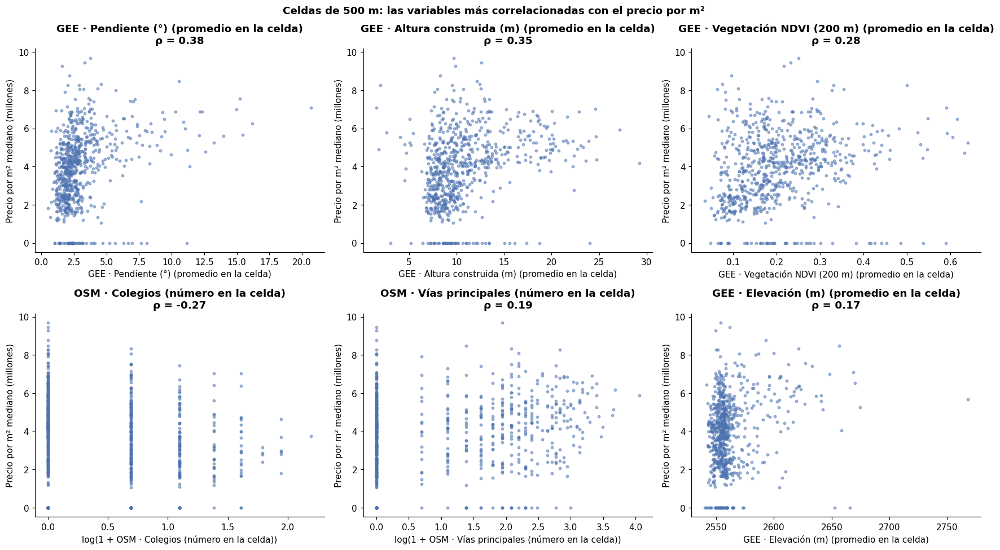

In [11]:
top = corr_celda.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, v in zip(axes.ravel(), top):
    xv = agg[v]
    ax.scatter(np.log1p(xv) if v.startswith("osm_") else xv, agg["precio_m2_mediano"], s=8, alpha=0.5, color="#4C72B0")
    ax.set(xlabel=f"log(1 + {es(v)})" if v.startswith("osm_") else es(v), ylabel="Precio por m² mediano (millones)",
           title=f"{es(v)}\nρ = {corr_celda.loc[v, 'Spearman precio/m² mediano']:.2f}")
fig.suptitle("Celdas de 500 m: las variables más correlacionadas con el precio por m²", fontweight="bold")
fig.tight_layout()
guardar(fig, "dispersion_celdas")
plt.show()

## 7. Autocorrelación espacial

### 7.1 I de Moran global de cada variable

Mide si los valores de ubicaciones cercanas se parecen ($I > 0$), son independientes ($I \approx 0$) o se oponen ($I < 0$).
Se calcula sobre ubicaciones únicas (promediando los avisos que comparten coordenadas), para que los duplicados no
inflen el resultado.

Matriz de pesos espaciales de $k = 10$ vecinos más cercanos, estandarizada por filas:

$$w_{ij}^{*} = \begin{cases} 1 & \text{si } j \text{ es uno de los } k \text{ vecinos más cercanos de } i \\ 0 & \text{si no}
\end{cases}, \qquad w_{ij} = \frac{w_{ij}^{*}}{\sum_{j} w_{ij}^{*}} = \frac{w_{ij}^{*}}{k}$$

I de Moran global para la variable $x$ en $n$ ubicaciones, con $z_i = x_i - \bar{x}$ y $S_0 = \sum_i \sum_j w_{ij}$
($= n$ con pesos estandarizados por filas):

$$I = \frac{n}{S_0} \, \frac{\sum_{i=1}^{n} \sum_{j=1}^{n} w_{ij}\, z_i z_j}{\sum_{i=1}^{n} z_i^2},
\qquad \mathbb{E}[I] = -\frac{1}{n - 1} \approx 0$$

Significancia por permutaciones: se reasignan al azar los valores entre ubicaciones $M = 199$ veces y se cuenta cuántas
veces el $I$ permutado es al menos tan extremo como el observado:

$$p = \frac{1 + \#\{m : I^{(m)} \ge I\}}{M + 1}$$

(con 199 permutaciones, el menor p-valor posible es 0,005).

In [12]:
from libpysal.weights import KNN
from esda.moran import Moran, Moran_Local


def moran_variable(d, var, k=10):
    u = d.groupby(["x", "y"], as_index=False)[var].mean().dropna()
    w = KNN.from_array(u[["x", "y"]].to_numpy(), k=k)
    w.transform = "r"
    mi = Moran(u[var].to_numpy(), w, permutations=199)
    return {"I de Moran": mi.I, "p-valor": mi.p_sim, "ubicaciones": len(u)}


moran = {}
for v in ["precio_mill", "log_precio", "precio_m2_mill"]:
    moran[v] = moran_variable(tr, v)
for v in ["surface_covered", "bedrooms", "bathrooms", "es_apartamento"] + GEE:
    moran[v] = moran_variable(gdf, v)
moran = pd.DataFrame(moran).T.sort_values("I de Moran", ascending=False)
guardar_tabla(moran.assign(nombre=moran.index.map(es)), "01_moran.csv")   # el p-valor por permutación puede variar
moran.rename(index=es).rename_axis("variable")

Coincide exactamente con stores/01_moran.csv


,I de Moran,p-valor,ubicaciones
variable,,,
Luces nocturnas,0.914,0.005,"22,015.000"
Altura construida (m),0.910,0.005,"22,015.000"
Elevación (m),0.868,0.005,"22,015.000"
Vegetación NDVI (200 m),0.846,0.005,"22,015.000"
Población (celda de 100 m),0.745,0.005,"22,015.000"
Pendiente (°),0.673,0.005,"22,015.000"
Es apartamento (0/1),0.524,0.005,"22,015.000"
Alcobas,0.391,0.005,"22,015.000"
Logaritmo del precio,0.343,0.005,"18,245.000"


### 7.2 Correlograma: ¿hasta qué distancia se parecen los precios?

Para cada banda de distancia $(a, b]$ se calcula la correlación entre los valores estandarizados de los pares de ubicaciones
que están a esa distancia (I de Moran por bandas). Con $\tilde{z}_i = (x_i - \bar{x}) / s_x$ y $d_{ij}$ la distancia
euclidiana en km entre $i$ y $j$:

$$I(a, b] = \frac{1}{|\mathcal{P}_{ab}|} \sum_{(i, j) \in \mathcal{P}_{ab}} \tilde{z}_i\, \tilde{z}_j,
\qquad \mathcal{P}_{ab} = \{(i, j) : i < j,\; a < d_{ij} \le b\}$$

Si $I(a, b] \approx 0$, los precios de ubicaciones separadas por esa distancia ya no se parecen: esa distancia indica el
alcance de la dependencia espacial. Se usa una submuestra de 4.000 ubicaciones de entrenamiento (~8 millones de pares).

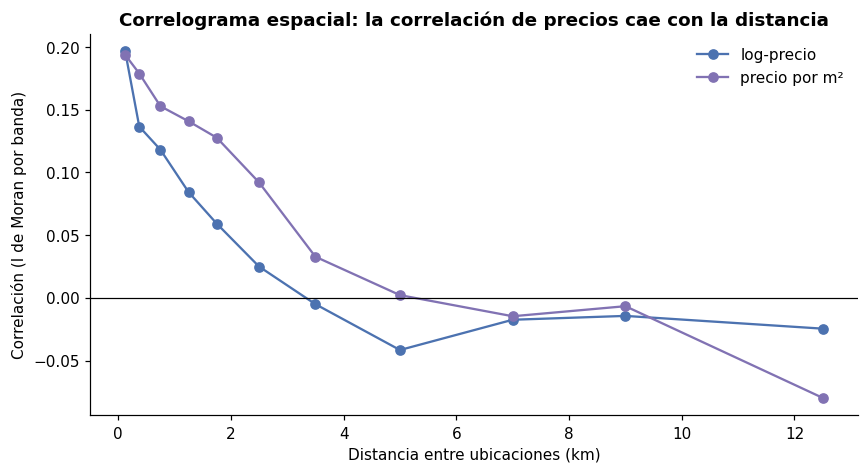

,Logaritmo del precio,Precio por m² (millones)
"distancia (km, centro de la banda)",,
0.125,0.196,0.194
0.375,0.136,0.179
0.750,0.118,0.153
1.250,0.084,0.141
1.750,0.059,0.128
2.500,0.025,0.092
3.500,-0.005,0.033
5.000,-0.042,0.002
7.000,-0.017,-0.015


In [13]:
def correlograma(d, var, bordes_km=(0, 0.25, 0.5, 1, 1.5, 2, 3, 4, 6, 8, 10, 15), n=4000):
    u = d.groupby(["x", "y"], as_index=False)[var].mean().dropna()
    u = u.sample(min(n, len(u)), random_state=SEMILLA)
    z = ((u[var] - u[var].mean()) / u[var].std()).to_numpy()
    xy = u[["x", "y"]].to_numpy()
    i, j = np.triu_indices(len(z), 1)                       # todos los pares (vectorizado)
    dist = np.hypot(xy[i, 0] - xy[j, 0], xy[i, 1] - xy[j, 1]) / 1000
    prod = z[i] * z[j]
    filas = []
    for a, b in zip(bordes_km[:-1], bordes_km[1:]):
        m = (dist > a) & (dist <= b)
        filas.append({"desde_km": a, "hasta_km": b, "centro_km": (a + b) / 2, "I": prod[m].mean(), "pares": int(m.sum())})
    return pd.DataFrame(filas)


cg = {v: correlograma(tr, v) for v in ["log_precio", "precio_m2_mill"]}
fig, ax = plt.subplots(figsize=(9, 4.5))
for v, c, nombre in [("log_precio", "#4C72B0", "log-precio"), ("precio_m2_mill", "#8172B3", "precio por m²")]:
    ax.plot(cg[v]["centro_km"], cg[v]["I"], "o-", color=c, label=nombre)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Correlograma espacial: la correlación de precios cae con la distancia",
       xlabel="Distancia entre ubicaciones (km)", ylabel="Correlación (I de Moran por banda)")
ax.legend(frameon=False)
guardar(fig, "correlograma")
plt.show()
pd.concat({es(k): v.set_index("centro_km")["I"] for k, v in cg.items()}, axis=1).rename_axis("distancia (km, centro de la banda)")

### 7.3 Clústeres locales del precio por m² (LISA)

I de Moran local (Anselin, 1995) para cada ubicación $i$, sobre $x = \ln(\text{precio/m}^2)$, con
$z_i = x_i - \bar{x}$ y $m_2 = \frac{1}{n}\sum_i z_i^2$:

$$I_i = \frac{z_i}{m_2} \sum_{j=1}^{n} w_{ij}\, z_j, \qquad \sum_{i=1}^{n} I_i = n \cdot I$$

El término $\sum_j w_{ij} z_j$ es el rezago espacial (promedio de los 10 vecinos). Cada ubicación significativa
($p_i < 0{,}05$, 199 permutaciones condicionales) se clasifica por cuadrante:

| Cuadrante | Condición | Interpretación |
|---|---|---|
| Alto-Alto | $z_i > 0$ y $\sum_j w_{ij} z_j > 0$ | Precio alto rodeado de precios altos |
| Bajo-Bajo | $z_i < 0$ y $\sum_j w_{ij} z_j < 0$ | Precio bajo rodeado de precios bajos |
| Alto-Bajo | $z_i > 0$ y $\sum_j w_{ij} z_j < 0$ | Atípico alto en zona barata |
| Bajo-Alto | $z_i < 0$ y $\sum_j w_{ij} z_j > 0$ | Atípico bajo en zona cara |

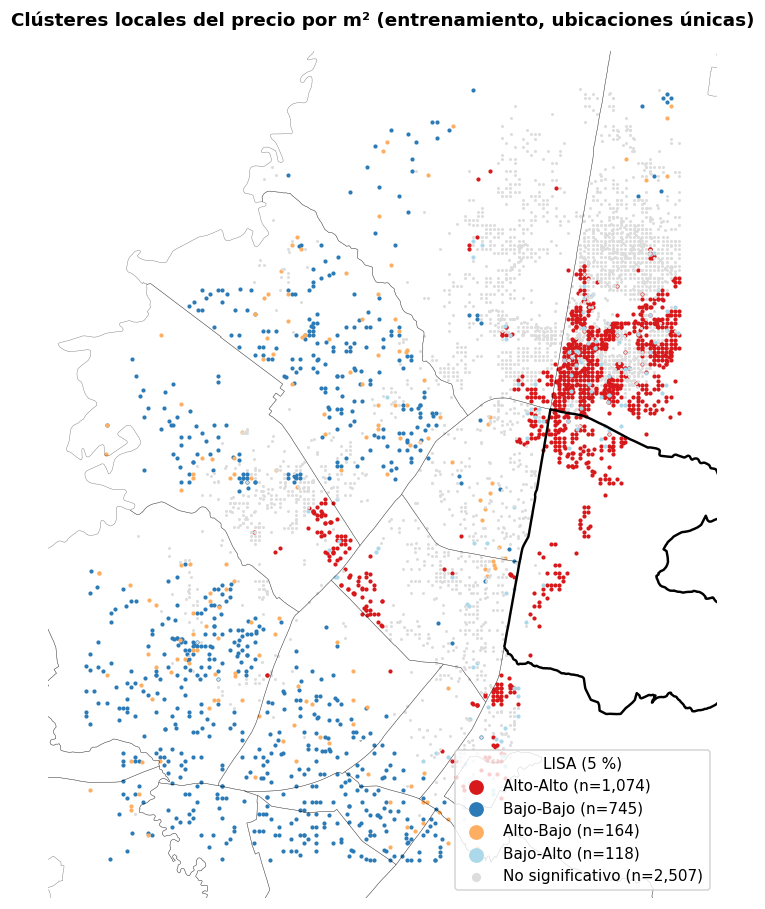

clúster LISA
No significativo    2507
Alto-Alto           1074
Bajo-Bajo            745
Alto-Bajo            164
Bajo-Alto            118
Name: ubicaciones, dtype: int64

In [14]:
u = tr.groupby(["x", "y"], as_index=False)["precio_m2_mill"].mean().dropna()
w = KNN.from_array(u[["x", "y"]].to_numpy(), k=10); w.transform = "r"
lisa = Moran_Local(np.log(u["precio_m2_mill"].to_numpy()), w, permutations=199, seed=SEMILLA)
etiquetas = {1: "Alto-Alto", 2: "Bajo-Alto", 3: "Bajo-Bajo", 4: "Alto-Bajo"}
u["lisa"] = np.where(lisa.p_sim < 0.05, pd.Series(lisa.q).map(etiquetas).values, "No significativo")
colores = {"Alto-Alto": "#d7191c", "Bajo-Bajo": "#2c7bb6", "Alto-Bajo": "#fdae61", "Bajo-Alto": "#abd9e9",
           "No significativo": "#dddddd"}
fig, ax = plt.subplots(figsize=(8, 10))
for cat_, col in colores.items():
    s = u[u["lisa"] == cat_]
    ax.scatter(s["x"], s["y"], s=3 if cat_ != "No significativo" else 1, color=col, label=f"{cat_} (n={len(s):,})")
mapa_base(ax)
ax.legend(markerscale=5, loc="lower right", frameon=True, title="LISA (5 %)")
ax.set_title("Clústeres locales del precio por m² (entrenamiento, ubicaciones únicas)")
guardar(fig, "lisa_precio_m2")
plt.show()
u["lisa"].value_counts().rename_axis("clúster LISA").rename("ubicaciones")

## 8. Precisión de las coordenadas: una parte de los avisos está en una malla de ~110 m

Los mapas en coordenadas exactas muestran que en el norte los puntos forman una grilla regular. La causa es que muchas
coordenadas vienen redondeadas a 3 decimales. Un grado de latitud mide ~111 km, así que el paso de la malla es:

$$\Delta = 0{,}001^{\circ} \times 111{,}32\ \tfrac{\text{km}}{\circ} \approx 111\ \text{m (latitud)}, \qquad
\Delta_{\text{lon}} = 0{,}001^{\circ} \times 111{,}32 \cos(4{,}65^{\circ}) \approx 111\ \text{m (longitud)}$$

Si la coordenada real se redondeó al punto de la malla más cercano, el error de posición está acotado por
$\max |e| \le \tfrac{\Delta}{2}\sqrt{2} \approx 79$ m. Para un error uniforme en la celda, el error esperado es de
$\mathbb{E}|e| \approx 0{,}38\,\Delta \approx 42$ m.

In [15]:
def n_decimales(v):
    return len(f"{v:.10f}".rstrip("0").split(".")[1])

gdf["decimales"] = np.maximum(gdf["lat"].map(n_decimales), gdf["lon"].map(n_decimales))
gdf["coord_redondeada"] = gdf["decimales"] <= 3
precision = pd.crosstab(gdf["decimales"].clip(upper=10), gdf["muestra"], normalize="columns").mul(100)[["train", "test"]]
precision.columns = [MUESTRA[c] for c in precision.columns]
precision.index.name = "decimales (máx. lat/lon)"
print("% de avisos según el número de decimales de la coordenada:")
precision.round(1)

% de avisos según el número de decimales de la coordenada:


,Entrenamiento,Prueba
decimales (máx. lat/lon),,
2,0.500,0.400
3,39.700,51.800
4,0.000,0.000
5,0.300,0.100
6,10.000,7.200
7,34.500,27.000
8,0.100,0.100
9,0.400,0.300
10,14.500,13.100


In [16]:
resumen_prec = gdf.groupby("coord_redondeada").agg(
    avisos=("property_id", "size"),
    coordenadas_unicas=("x", lambda s: gdf.loc[s.index].groupby(["x", "y"]).ngroups),
    pct_test=("muestra", lambda s: 100 * (s == "test").mean()),
    pct_chapinero=("zona", lambda s: 100 * (s == "Chapinero").mean()),
    precio_mediano_train=("precio_mill", "median"))
resumen_prec["avisos por coordenada"] = resumen_prec["avisos"] / resumen_prec["coordenadas_unicas"]
resumen_prec.index = resumen_prec.index.map({True: "Redondeada (≤ 3 decimales)", False: "Precisa (> 3 decimales)"})
resumen_prec.rename(columns={"avisos": "Avisos", "coordenadas_unicas": "Coordenadas únicas", "pct_test": "% de prueba",
                             "pct_chapinero": "% en Chapinero", "precio_mediano_train": "Precio mediano entrenamiento (millones)",
                             "avisos por coordenada": "Avisos por coordenada"}).rename_axis("Tipo de coordenada").round(1)

,Avisos,Coordenadas únicas,% de prueba,% en Chapinero,Precio mediano entrenamiento (millones),Avisos por coordenada
Tipo de coordenada,,,,,,
Precisa (> 3 decimales),28040,17966,17.500,16.600,550.000,1.600
Redondeada (≤ 3 decimales),20890,4049,25.700,25.600,570.000,5.200


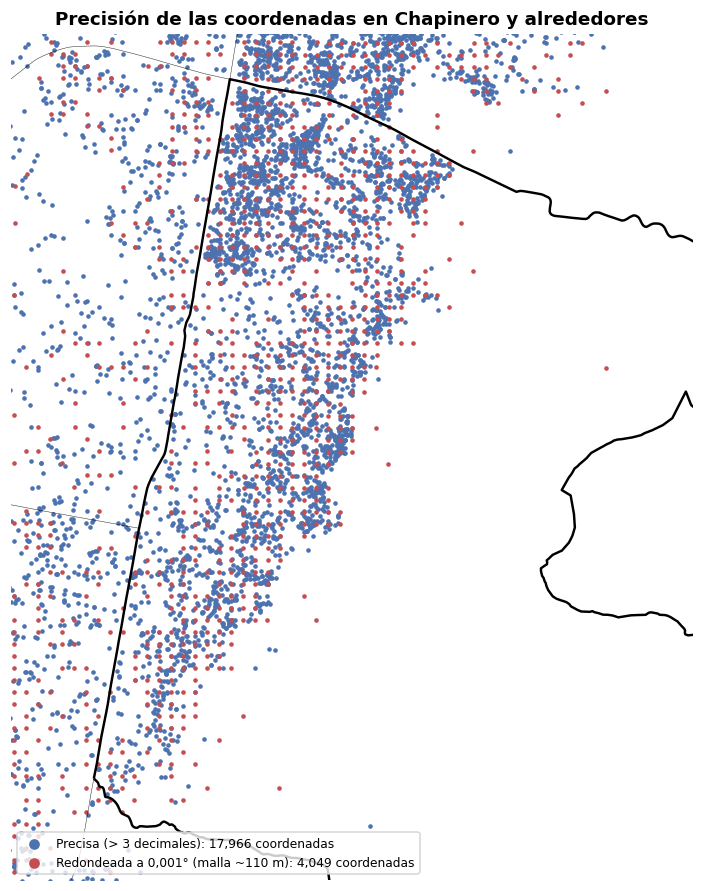

In [17]:
zoom = gdf[gdf["zona"] == "Chapinero"].total_bounds + np.array([-800, -500, 800, 500])
fig, ax = plt.subplots(figsize=(8, 10))
u = gdf.drop_duplicates(["x", "y"])
for red, col, et in [(False, "#4C72B0", "Precisa (> 3 decimales)"), (True, "#C44E52", "Redondeada a 0,001° (malla ~110 m)")]:
    s = u[u["coord_redondeada"] == red]
    ax.scatter(s["x"], s["y"], s=4, color=col, label=f"{et}: {len(s):,} coordenadas")
mapa_base(ax, zoom)
ax.legend(loc="lower left", frameon=True, markerscale=3, fontsize=8)
ax.set_title("Precisión de las coordenadas en Chapinero y alrededores")
guardar(fig, "precision_coordenadas")
plt.show()

## 9. Texto como datos: del título y la descripción a variables

Se sigue el marco de Gentzkow, Kelly y Taddy (2019, Text as Data, JEL) con las recetas de la clase (*Texto como datos
(k)*, Texto como datos, Procesamiento del Lenguaje Natural y Lecture 15), y se complementa con Ash y Hansen (2023, *Text
Algorithms in Economics*, ARE):

El texto crudo $\mathcal{D}$ se representa como una matriz numérica $\mathbf{C}$; de ella se miden atributos
$\hat{\mathbf{V}}$, y esos atributos entran al modelo que predice $\hat y$.

1. Representación (Gentzkow et al., sec. 2): limpieza, tokenización, stopwords, stemming, n-gramas y filtros de
   frecuencia. El resultado es la matriz documento–término $\mathbf{C} = [c_{ij}]$, con $c_{ij}$ = número de veces que el término
   $j$ aparece en el documento (aviso) $i$.
2. Medición: Gentzkow et al. (sec. 3, pp. 541–542) clasifican los métodos en (i) diccionarios (patrones definidos por el
   investigador), (ii) regresión de texto supervisada, (iii) modelos generativos (tópicos) y (iv) embeddings. Ash y
   Hansen complementan con representaciones densas y transformers (pp. 666–668).
3. En este cuaderno se construyen (i), las cantidades extraídas, los vectores TF-IDF, la reducción de dimensión no supervisada
   (LSA) y los tópicos (iii). La regresión de texto (ii) usa el precio y se deja para la modelación, dentro de los pliegues.

El documento de cada aviso es el título seguido de la descripción.

In [18]:
import re
import unicodedata
from collections import Counter

DIR_TEXTO = STORES / "texto"

corpus = (gdf["title"].fillna("") + " . " + gdf["description"].fillna("")).astype(str)
n_palabras = corpus.str.split().str.len()
print(f"Documentos: {len(corpus):,} | palabras por documento: mediana {n_palabras.median():.0f}, "
      f"p90 {n_palabras.quantile(.9):.0f}, máx {n_palabras.max():,}")
pd.DataFrame({"Entrenamiento": n_palabras[gdf["muestra"] == "train"].describe(),
              "Prueba": n_palabras[gdf["muestra"] == "test"].describe()}).T.round(1)

Documentos: 48,930 | palabras por documento: mediana 67, p90 121, máx 614


,count,mean,std,min,25%,50%,75%,max
Entrenamiento,"38,644.000",73.700,36.900,4.000,48.000,67.000,89.000,612.000
Prueba,"10,286.000",72.300,36.300,3.000,47.000,66.000,88.000,614.000


### 9.1 Normalización

Gentzkow et al. (pp. 538–539) señalan que cada paso de preprocesamiento "requiere decisiones cuidadosas" según la aplicación.
Estos avisos ya vienen en minúsculas y sin tildes, pero tienen problemas propios de la exportación de Properati y del
enmascaramiento de la competencia:

| Problema | Ejemplo | Tratamiento |
|---|---|---|
| Números enmascarados por Kaggle | `administracion X`, `celular XX`, `ref XXX` | Se eliminan las máscaras `X+`. Por eso no existen precios, administración ni teléfonos en el texto (no se extraen) |
| Entidades HTML partidas en palabras | ba ntilde o, balc oacute n, aacute rea | Se reconstruye la palabra (baño, balcón, área) |
| Letras perdidas (ñ y vocales tildadas) | saln, balcn, habitacin, nios, aos | Regla de inserción basada en frecuencias del corpus (abajo) |
| Abreviaturas y variantes del dominio | apto, mts, m 2, hab, garage, admon | Mapa de dominio (como el `dict_lemas` de ConTexto) |
| Números escritos con letras y ordinales | dos alcobas, cuarto piso | Se convierten a dígitos (2 alcoba, piso 4) |
| Dígitos pegados a letras | 3alcobas, 120m2 | Se separan (regex de clase) |
| Firmas de agentes | comunicarse con andres nieto | Se eliminan nombres y apellidos de las listas del DNP solo tras expresiones de contacto |

Regla de las letras perdidas. Sea $df(t)$ el número de documentos que contienen el token $t$ y
$\mathcal{C}(t) = \{t_{1:k}\, c\, t_{k+1:\ell} : k = 0, \dots, \ell,\ c \in \{\text{n}, \text{a}, \text{e}, \text{i}, \text{o}, \text{u}\}\}$
las palabras que resultan de insertar una de esas letras. Se reemplaza

$$t \mapsto t^{*} = \arg\max_{s \in \mathcal{C}(t)} df(s) \qquad \text{si} \quad df(t^{*}) \ge \max\{20,\ 2\, df(t)\}$$

Las correcciones se guardan en `stores/texto/auditoria_correcciones.csv` para auditarlas a mano, como recomiendan Gentzkow
et al. (p. 555).

In [19]:
def sin_tildes(s):
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode("ascii")


NUMEROS = {"un": 1, "una": 1, "uno": 1, "dos": 2, "tres": 3, "cuatro": 4, "cinco": 5, "seis": 6, "siete": 7,
           "ocho": 8, "nueve": 9, "diez": 10}
ORDINALES = {"primer": 1, "primero": 1, "segundo": 2, "tercer": 3, "tercero": 3, "cuarto": 4, "quinto": 5,
             "sexto": 6, "septimo": 7, "octavo": 8, "noveno": 9, "decimo": 10}
MAPA_DOMINIO = [  # (patrón, reemplazo): abreviaturas y variantes del dominio inmobiliario
    (r"\b(?:m|mt|mts)\s*2\b|\bmts\b|\bmetros? cuadrados?\b", " m2 "),          # "m 2" aparece tras separar dígitos y letras
    (r"\baptos?\b|\bapartamentos?\b", " apartamento "),
    (r"\bhabs?\b|\bhabitaciones?\b|\bcuartos\b|\bcuarto\b(?!\s+(?:piso|nivel|util))|\bdormitorios?\b", " alcoba "),
    (r"\balcobas\b", " alcoba "),
    (r"\bparq\b|\bparqueaderos?\b|\bgarajes?\b|\bgarages?\b|\bparqueos?\b", " parqueadero "),
    (r"\badmon\b|\badmin\b|\badmi\b|\badministracion\b", " administracion "),
    (r"\bbanos\b", " bano "),
]
RE_MASCARA = re.compile(r"\bX+\b")                                    # máscaras de números de la competencia
RE_WWW = re.compile(r"\bwww(?:\s+[a-z0-9]+){1,3}?\s+com(?:\s+co)?\b|https?://\S+|\S+@\S+")
RE_HTML = re.compile(r"<[^>]+>|&nbsp;|&amp;|&#?\w+;")
RE_ENT_TILDE = re.compile(r"&([a-zA-Z])(?:tilde|acute|grave|uml|circ);")
RE_ORDINAL = re.compile(r"\b(" + "|".join(ORDINALES) + r")\s+(piso|nivel)\b")
RE_NUMEROS = re.compile(r"\b(" + "|".join(NUMEROS) + r")\b(?=\s+(?:alcoba|bano|parqueadero|piso|nivel|ambientes?))")
FUNCIONALES = {"de", "la", "el", "en", "y", "a", "con", "los", "las", "del", "para", "por", "un", "una", "al", "su", "sus",
               "se", "que", "o", "es", "muy", "mas", "sin", "no"}


def reparar_entidades(t):
    """'ba ntilde o' -> 'bano'; 'balc oacute n' -> 'balcon'; 'de aacute rea' -> 'de area'."""
    pal = t.split()
    out, i = [], 0
    while i < len(pal):
        m = re.fullmatch(r"([a-z])(acute|tilde|grave|uml|circ)", pal[i])
        if not m:
            out.append(pal[i]); i += 1
            continue
        letra = m.group(1)
        # se une con la palabra anterior si es un fragmento (no una palabra funcional) y con la siguiente si es corta
        izq = out.pop() if out and out[-1].isalpha() and out[-1] not in FUNCIONALES else ""
        der = ""
        if i + 1 < len(pal) and pal[i + 1].isalpha() and (pal[i + 1] not in FUNCIONALES or len(pal[i + 1]) <= 2):
            der = pal[i + 1]; i += 1
        out.append(izq + letra + der)
        i += 1
    return " ".join(out)


def normalizar(texto):
    t = RE_MASCARA.sub(" ", str(texto))                              # antes de pasar a minúsculas (las máscaras son "X")
    t = RE_ENT_TILDE.sub(r"\1", t)
    t = RE_HTML.sub(" ", t)
    t = sin_tildes(t.lower())
    t = RE_WWW.sub(" ", t)
    t = re.sub(r"\bbr\b", " ", t)
    t = reparar_entidades(t)
    t = re.sub(r"(?<=\d)(?=[a-z])|(?<=[a-z])(?=\d)", " ", t)       # 3alcobas -> 3 alcobas (regex de clase)
    t = RE_ORDINAL.sub(lambda m: f"{m.group(2)} {ORDINALES[m.group(1)]}", t)
    for patron, reemplazo in MAPA_DOMINIO:
        t = re.sub(patron, reemplazo, t)
    t = RE_NUMEROS.sub(lambda m: str(NUMEROS[m.group(1)]), t)
    t = re.sub(r"[^a-z0-9 ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()


texto = corpus.map(normalizar)

# --- Regla de las letras perdidas (ñ y vocales tildadas) ---
PERDIDAS = "naeiou"
PROTEGIDAS = {"vistas", "nos", "com", "star", "sal", "chic", "cer"}   # falsos positivos detectados en la auditoría
df_tok = Counter(w for doc in texto for w in set(re.findall(r"[a-z]{3,}", doc)))
mapa_letras = {}
for t, f in df_tok.items():
    if t in PROTEGIDAS:
        continue
    cand = max({t[:k] + c + t[k:] for k in range(len(t) + 1) for c in PERDIDAS}, key=lambda s: df_tok.get(s, 0))
    if df_tok.get(cand, 0) >= max(20, 2 * f):
        mapa_letras[t] = cand
for t in mapa_letras:                                 # cadenas: balc -> balcn -> balcon
    vistos = {t}
    while mapa_letras[t] in mapa_letras and mapa_letras[t] not in vistos:
        vistos.add(mapa_letras[t])
        mapa_letras[t] = mapa_letras[mapa_letras[t]]
re_letras = re.compile(r"\b(" + "|".join(map(re.escape, sorted(mapa_letras, key=len, reverse=True))) + r")\b")
texto = texto.str.replace(re_letras, lambda m: mapa_letras[m.group(1)], regex=True)


def remapear(t):                                      # después de corregir: habitacin -> habitacion -> alcoba
    for patron, reemplazo in MAPA_DOMINIO:
        t = re.sub(patron, reemplazo, t)
    t = RE_NUMEROS.sub(lambda m: str(NUMEROS[m.group(1)]), t)
    return re.sub(r"\s+", " ", t).strip()


texto = texto.map(remapear)
auditoria_corr = pd.DataFrame({"original": list(mapa_letras), "corregido": list(mapa_letras.values()),
                               "df_original": [df_tok[t] for t in mapa_letras],
                               "df_corregido": [df_tok.get(c, 0) for c in mapa_letras.values()]}).sort_values("df_original", ascending=False)
guardar_tabla(auditoria_corr, "auditoria_correcciones.csv", DIR_TEXTO, index=False)
print(f"Formas corregidas por la regla de letras perdidas: {len(mapa_letras):,}")
auditoria_corr.head(20)

Coincide con texto/auditoria_correcciones.csv (mismas filas; cambia el orden entre empates)
Formas corregidas por la regla de letras perdidas: 1,210


,original,corregido,df_original,df_corregido
19,bao,bano,7039,28507
23,lavandera,lavanderia,3597,11593
9,saln,salon,3451,10855
7,balcn,balcon,2958,8871
22,vas,vias,2646,8451
16,depsito,deposito,2125,16158
18,iluminacin,iluminacion,1964,5105
24,rea,area,1796,7541
6,habitacin,habitacion,1587,5665
36,ubicacin,ubicacion,1464,6000


### 9.1b Corrección ortográfica con el modelo de lenguaje de BETO

Además de las letras perdidas, los avisos tienen errores de digitación (chimemea, tranquildad, apartamendos,
cuadados). Se corrigen con el mismo modelo BETO que se usa para los embeddings (sección 10), aprovechando su modelo de
lenguaje enmascarado (MLM): BETO se entrenó tapando palabras y prediciéndolas a partir del contexto, así que puede decir qué
palabra encaja en una posición. Esta es la idea de corrección con contexto que ConTexto (DNP) hace con diccionarios, pero
usando el contexto de todo el aviso.

1. Palabras sospechosas. Palabras de 4 o más letras que aparecen en menos de 5 avisos y que no existen en el vocabulario
de BETO (ni sin tilde ni con tilde): $\mathcal{S} = \{w : df(w) < 5,\ |w| \ge 4,\ w \notin \mathcal{V}\}$.

2. Candidatas. Palabras frecuentes del corpus ($df \ge 20$) que son una sola palabra del vocabulario de BETO y están a
distancia de Damerau-Levenshtein $\text{DL}$ (inserción, borrado, sustitución o transposición) de a lo sumo $n(w)$:

$$\mathcal{C}(w) = \{v : df(v) \ge 20,\ v \in \mathcal{V},\ \text{DL}(w, v) \le n(w)\}, \qquad n(w) = \begin{cases} 1 & |w| < 6 \\ 2 & |w| \ge 6 \end{cases}$$

3. Elección con el contexto. En hasta 2 avisos donde aparece $w$, se reemplaza $w$ por `[MASK]` (ventana de ±40 palabras,
con tildes restauradas como en la sección 10.3) y BETO da la probabilidad de cada candidata en esa posición, a partir del
vector de la última capa $\mathbf{h}^{(12)}_t$:

$$P(v \mid \mathbf{d}_{\setminus t}) = \operatorname{softmax}\big(\mathbf{W}_{\text{MLM}}\, g(\mathbf{h}^{(12)}_t) + \mathbf{b}\big)_v,
\qquad s(v) = \frac{1}{|\mathcal{K}_w|} \sum_{k \in \mathcal{K}_w} \log P(v \mid \mathbf{d}^{(k)}_{\setminus t}), \qquad
\hat{w} = \arg\max_{v \in \mathcal{C}(w)} s(v)$$

4. Aceptación conservadora (para no "corregir" palabras válidas): se acepta $\hat{w}$ si $s(\hat{w}) \ge -3$, o si
$s(\hat{w}) \ge -5$ y $\text{DL}(w, \hat{w}) = 1$; nunca si la única diferencia es una "s" final (plural válido). Todas las
correcciones quedan en `stores/texto/auditoria_ortografia_beto.csv` para revisarlas a mano.

Ejecución. Este paso usa BETO en GPU. Con `RECALCULAR = False` no se vuelve a correr: se aplican las correcciones
aceptadas que quedaron en la auditoría. Salida de la ejecución original (GPU RTX 5060, 23 de noviembre de 2026):
8.646 palabras sospechosas, 3.652 con candidatas, 4.902 contextos evaluados en unos 38 segundos, 732 formas
corregidas y 971 avisos modificados.

In [20]:
# Con RECALCULAR: BETO (modelo de lenguaje enmascarado) elige y acepta las correcciones; usa la GPU si existe.
# Sin RECALCULAR: se aplican las correcciones aceptadas en la ejecución original (auditoría guardada).
from collections import defaultdict

if RECALCULAR:
    import torch
    from collections import defaultdict
    from transformers import AutoTokenizer, AutoModelForMaskedLM

    MODELO_BETO = "dccuchile/bert-base-spanish-wwm-uncased"
    tok_beto = AutoTokenizer.from_pretrained(MODELO_BETO)
    VOC_BETO = tok_beto.get_vocab()
    ACENTUADAS = {}
    for w in sorted((w for w in VOC_BETO if not w.startswith("##") and w.isalpha()), key=VOC_BETO.get):
        s = sin_tildes(w)
        if s != w and s not in VOC_BETO and s not in ACENTUADAS:
            ACENTUADAS[s] = w
    ACENTUADAS.update({"ano": "año", "anos": "años", "bano": "baño", "banos": "baños"})
    forma_beto = lambda w: w if w in VOC_BETO else ACENTUADAS.get(w)


    def borrados(w, n):
        res, frente = {w}, {w}
        for _ in range(n):
            frente = {x[:i] + x[i + 1:] for x in frente for i in range(len(x))}
            res |= frente
        return res


    def damerau_levenshtein(a, b):
        """Distancia de Damerau-Levenshtein (alineamiento óptimo de cadenas)."""
        m, n = len(a), len(b)
        D = [[0] * (n + 1) for _ in range(m + 1)]
        for i in range(m + 1):
            D[i][0] = i
        for j in range(n + 1):
            D[0][j] = j
        for i in range(1, m + 1):
            for j in range(1, n + 1):
                D[i][j] = min(D[i - 1][j] + 1, D[i][j - 1] + 1, D[i - 1][j - 1] + (a[i - 1] != b[j - 1]))
                if i > 1 and j > 1 and a[i - 1] == b[j - 2] and a[i - 2] == b[j - 1]:
                    D[i][j] = min(D[i][j], D[i - 2][j - 2] + 1)
        return D[m][n]


    df_pal = Counter(w for doc in texto for w in set(re.findall(r"[a-z]{3,}", doc)))
    sospechosas = [w for w, f in df_pal.items() if f < 5 and len(w) >= 4 and forma_beto(w) is None]
    indice = defaultdict(set)
    for v in (w for w, f in df_pal.items() if f >= 20 and forma_beto(w) is not None):
        for b in borrados(v, 2):
            indice[b].add(v)
    candidatas = {}
    for w in sospechosas:
        n = 1 if len(w) < 6 else 2
        c = {v for v in set().union(*(indice.get(b, set()) for b in borrados(w, n))) if damerau_levenshtein(w, v) <= n}
        if c:
            candidatas[w] = c

    contextos = defaultdict(list)
    docs_pal = texto.str.split().tolist()
    for k, pal in enumerate(docs_pal):
        for w in set(pal) & candidatas.keys():
            if len(contextos[w]) < 2:
                p = pal.index(w)
                ventana = ([ACENTUADAS.get(x, x) for x in pal[max(0, p - 40):p]] + [tok_beto.mask_token]
                           + [ACENTUADAS.get(x, x) for x in pal[p + 1:p + 41]])
                contextos[w].append(" ".join(ventana))
    items = [(w, c) for w, cs in contextos.items() for c in cs]

    dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
    mlm = AutoModelForMaskedLM.from_pretrained(MODELO_BETO).to(dispositivo).eval()
    puntajes = defaultdict(lambda: defaultdict(list))
    with torch.inference_mode(), torch.autocast(device_type=dispositivo, dtype=torch.float16, enabled=dispositivo == "cuda"):
        for i in range(0, len(items), 128):
            lote = items[i:i + 128]
            enc = tok_beto([c for _, c in lote], padding=True, truncation=True, max_length=128, return_tensors="pt").to(dispositivo)
            logp = torch.log_softmax(mlm(**enc).logits.float(), dim=-1)
            for fila, col in (enc["input_ids"] == tok_beto.mask_token_id).nonzero().tolist():
                w = lote[fila][0]
                for v in candidatas[w]:
                    puntajes[w][v].append(logp[fila, col, VOC_BETO[forma_beto(v)]].item())
    del mlm
    if dispositivo == "cuda":
        torch.cuda.empty_cache()

    filas = []
    for w, ps in puntajes.items():
        v, s = max(((v, float(np.mean(x))) for v, x in ps.items()), key=lambda t: t[1])
        dist = damerau_levenshtein(w, v)
        solo_plural = w == v + "s" or v == w + "s"
        acepta = (not solo_plural) and (s >= -3 or (s >= -5 and dist == 1))
        filas.append({"original": w, "correccion": v, "log_prob": s, "distancia": dist, "df_original": df_pal[w],
                      "df_correccion": df_pal[v], "aceptada": acepta})
    auditoria_ort = pd.DataFrame(filas).sort_values("log_prob", ascending=False)
    guardar_tabla(auditoria_ort, "auditoria_ortografia_beto.csv", DIR_TEXTO, index=False)
    print(f"Palabras sospechosas: {len(sospechosas):,} | con candidatas: {len(candidatas):,} | contextos evaluados: {len(items):,}")
else:
    auditoria_ort = pd.read_csv(DIR_TEXTO / "auditoria_ortografia_beto.csv")
    print(f"Auditoría guardada: {len(auditoria_ort):,} palabras con candidata, "
          f"{int(auditoria_ort['aceptada'].sum()):,} correcciones aceptadas")

mapa_ort = dict(auditoria_ort.loc[auditoria_ort["aceptada"], ["original", "correccion"]].values)
re_ort = re.compile(r"\b(" + "|".join(map(re.escape, sorted(mapa_ort, key=len, reverse=True))) + r")\b")
antes_ort = texto.copy()
texto = texto.str.replace(re_ort, lambda m: mapa_ort[m.group(1)], regex=True)
print(f"Correcciones aceptadas: {len(mapa_ort):,} formas | avisos modificados: {(antes_ort != texto).sum():,}")
pd.concat([auditoria_ort[auditoria_ort["aceptada"]].head(12).assign(grupo="aceptadas (mayor confianza)"),
           auditoria_ort[~auditoria_ort["aceptada"]].head(8).assign(grupo="rechazadas (ejemplos)")]).round(3)

Auditoría guardada: 3,652 palabras con candidata, 732 correcciones aceptadas


Correcciones aceptadas: 732 formas | avisos modificados: 971


,original,correccion,log_prob,distancia,df_original,df_correccion,aceptada,grupo
0,sante,santa,-0.000,1,1,6475,True,aceptadas (mayor confianza)
1,sangta,santa,-0.000,1,1,6475,True,aceptadas (mayor confianza)
2,santra,santa,-0.000,1,1,6475,True,aceptadas (mayor confianza)
3,imperia,imperial,-0.000,1,2,58,True,aceptadas (mayor confianza)
4,desanta,santa,-0.001,2,1,6475,True,aceptadas (mayor confianza)
5,sauiza,suiza,-0.002,1,1,1134,True,aceptadas (mayor confianza)
6,venevia,venecia,-0.003,1,1,75,True,aceptadas (mayor confianza)
7,estadom,estado,-0.003,1,2,3042,True,aceptadas (mayor confianza)
8,balla,bella,-0.003,1,1,1271,True,aceptadas (mayor confianza)
9,florez,flores,-0.003,1,4,35,True,aceptadas (mayor confianza)


Firmas de agentes inmobiliarios. Se usan las listas de nombres y apellidos de ConTexto (DNP)
(`stores/texto/contexto_dnp/`). Como muchas coinciden con barrios (chico, cabrera, rosales, retiro) y con palabras
comunes (de, para, casa, sala), primero se les quitan las stopwords y ese vocabulario, y luego solo se borran en las
4 palabras que siguen a una expresión de contacto.

In [21]:
def cargar_lista(nombre):
    crudo = (STORES / "texto" / "contexto_dnp" / f"lista_{nombre}.txt").read_bytes()
    for cod in ("utf-8", "latin-1"):
        try:
            txt = crudo.decode(cod)
            break
        except UnicodeDecodeError:
            continue
    return {sin_tildes(l.strip().lower()) for l in txt.splitlines() if l.strip()}


NOMBRES_DNP = (cargar_lista("nombres_ambos") | cargar_lista("nombres_hombres") | cargar_lista("nombres_mujeres")
               | cargar_lista("apellidos"))
NOMBRES_DNP -= cargar_lista("sw_es") | FUNCIONALES | {"casa", "sala", "mayor", "hermoso", "linda", "bella", "real", "alta",
                                                       "chico", "cabrera", "rosales", "retiro", "andino", "castillo", "prado"}
RE_CONTACTO = re.compile(r"\b(contactame|contactenos|contacteme|contactarse con|contactar a|comunicate con|comuniquese con|"
                         r"comunicarse con|llamar a|llamar al|llama a|al celular|asesora?|agente|informes con|pregunta por|"
                         r"preguntar por|escribir a|atendido por)\b((?:\s+[a-z]+){1,4})")


def quitar_firma(t):
    def limpiar(m):
        return " " + m.group(1) + " " + " ".join(w for w in m.group(2).split() if w not in NOMBRES_DNP) + " "
    return RE_CONTACTO.sub(limpiar, t)


antes = texto.copy()
texto = texto.map(quitar_firma).str.replace(r"\s+", " ", regex=True).str.strip()
cambiados = antes != texto
print(f"Avisos con firma de agente eliminada: {cambiados.sum():,} ({100 * cambiados.mean():.1f} %)")


def fragmento(a, b, ancho=70):
    """Muestra la parte del texto donde cambió."""
    k = next((i for i, (u, v) in enumerate(zip(a, b)) if u != v), 0)
    return a[max(0, k - 25):k + ancho], b[max(0, k - 25):k + ancho]


ej = [fragmento(a, b) for a, b in zip(antes[cambiados].head(5), texto[cambiados].head(5))]
pd.DataFrame(ej, columns=["antes", "después"])

Avisos con firma de agente eliminada: 1,424 (2.9 %)


,antes,después
0,ormacion comunicarse con andres nieto al celular,ormacion comunicarse con nieto al celular
1,ormacion comunicarse con andres nieto al celular,ormacion comunicarse con nieto al celular
2,ormacion comunicarse con andres nieto al celular,ormacion comunicarse con nieto al celular
3,ormacion comunicarse con andres nieto al celular,ormacion comunicarse con nieto al celular
4,ormacion comunicarse con andres nieto al celular,ormacion comunicarse con nieto al celular


### 9.2 Duplicados de texto

Un mismo inmueble suele publicarse varias veces con el mismo texto. Si dos copias quedan en pliegues distintos de la
validación, el modelo "reconoce" el aviso y el error se subestima (fuga entre pliegues). Se identifican grupos con la huella
(hash) del texto normalizado; en la modelación, cada grupo debe quedar entero en un mismo pliegue, y las variables que usan
el precio de los vecinos deben excluir a los duplicados.

In [22]:
import hashlib
huella = texto.map(lambda s: hashlib.md5(s.encode()).hexdigest())
gdf["grupo_texto"] = huella.values
es_tr = (gdf["muestra"] == "train").values
huellas_tr = set(huella[es_tr])
dup = pd.Series({
    "Documentos": len(texto),
    "Textos distintos (tras normalizar)": huella.nunique(),
    "% de avisos de entrenamiento con texto repetido": 100 * huella[es_tr].duplicated(keep=False).mean(),
    "% de avisos de prueba con texto repetido (dentro de prueba)": 100 * huella[~es_tr].duplicated(keep=False).mean(),
    "% de avisos de prueba con gemelo exacto en entrenamiento": 100 * huella[~es_tr].isin(huellas_tr).mean(),
})
dup.to_frame("valor")

,valor
Documentos,"48,930.000"
Textos distintos (tras normalizar),"41,744.000"
% de avisos de entrenamiento con texto repetido,22.775
% de avisos de prueba con texto repetido (dentro de prueba),24.295
% de avisos de prueba con gemelo exacto en entrenamiento,0.758


### 9.3 Métodos de diccionario: características con manejo de negación

Primer grupo de métodos de Gentzkow et al. (pp. 541–542): contar términos definidos por el investigador. Se replica la función
`detectar_caracteristica` de la clase (Texto como datos (k)): primero se borran las menciones negadas y luego se busca el
patrón. Para la característica $k$ con patrón $\mathcal{P}_k$:

$$I_{ik} = \mathbb{1}\big\{\mathcal{P}_k \text{ aparece en } \tilde{d}_i\big\}, \qquad
\tilde{d}_i = d_i \text{ sin las coincidencias de } \big(\text{sin} \mid \text{no }(\text{tiene} \mid \text{cuenta con} \mid
\text{dispone de} \mid \text{hay} \mid \text{incluye})\big)\ (\text{un} \mid \text{una} \mid \text{el} \mid \text{la} \mid
\text{los} \mid \text{las})^{?}\ \mathcal{P}_k$$

Se usan los 8 indicadores de clase (con sus variantes de patrón: zonas sociales, salón de reuniones, remodelación,
cocinas integrales) más extensiones relevantes para Chapinero según el análisis exploratorio.

In [23]:
NEGACION = r"\b(?:sin|no\s+(?:tiene|cuenta\s+con|dispone\s+de|hay|incluye))\s+(?:(?:un|una|el|la|los|las)\s+)?(?:{p})"
CARACTERISTICAS = {
    # --- Ocho indicadores de la clase ---
    "parqueadero": r"parqueadero", "piscina": r"piscina|jacuzzi", "ascensor": r"ascensor",
    "terraza_balcon": r"terraza|balcon", "vigilancia": r"vigilancia|seguridad|porteria|portero",
    "remodelado": r"remodelad|remodelo\b|renovad|(?<!requiere )(?<!necesita )(?<!para )remodelacion",
    "cocina_integral": r"cocinas?\s+integral",
    "zona_social": r"zonas?\s+social(?:es)?|salon(?:es)?\s+(?:social(?:es)?|comunal(?:es)?|de\s+reuniones)",
    # --- Extensiones ---
    "chimenea": r"chimenea", "vista": r"vista|panoramic", "estudio": r"estudio", "apartaestudio": r"apartaestudio|aparta estudio|loft",
    "duplex_penthouse": r"duplex|penthouse|pent house", "exterior": r"exterior", "gimnasio": r"gimnasio|gym",
    "deposito": r"deposito|bodega", "conjunto": r"conjunto cerrado|conjunto", "nuevo_estrenar": r"para estrenar|estrenar|sobre planos|proyecto nuevo",
}
for nombre, patron in CARACTERISTICAS.items():
    limpio = texto.str.replace(NEGACION.format(p=patron), " ", regex=True)
    gdf[f"txt_{nombre}"] = limpio.str.contains(rf"\b(?:{patron})", regex=True).astype(int).values
gdf["txt_para_remodelar"] = texto.str.contains(r"para remodelar|requiere remodela|necesita remodela|para reformar").astype(int).values
VARS_DICC = [c for c in gdf.columns if c.startswith("txt_")]

negadas = {n: int(texto.str.contains(rf"\b(?:{p})").sum() - gdf[f"txt_{n}"].sum()) for n, p in CARACTERISTICAS.items()}
tab_dicc = pd.DataFrame({
    "% entrenamiento": 100 * gdf.loc[es_tr, VARS_DICC].mean(),
    "% prueba": 100 * gdf.loc[~es_tr, VARS_DICC].mean(),
    "menciones negadas descartadas": pd.Series({f"txt_{k}": v for k, v in negadas.items()}),
}).fillna(0)
tab_dicc.index = [i.replace("txt_", "") for i in tab_dicc.index]
tab_dicc.sort_values("% prueba", ascending=False).round(1)

,% entrenamiento,% prueba,menciones negadas descartadas
parqueadero,70.100,69.500,63.000
terraza_balcon,46.200,49.300,3.000
deposito,40.300,40.300,117.000
zona_social,32.400,33.400,7.000
vista,23.800,32.700,0.000
estudio,35.200,31.600,0.000
chimenea,23.500,30.000,0.000
exterior,22.700,28.400,0.000
vigilancia,25.000,26.300,38.000
gimnasio,23.800,24.500,0.000


### 9.4 Extracción de cantidades del texto

La clase sugiere usar la descripción para llenar faltantes en lugar de imputar con un modelo (Texto como datos (k),
nota 3). Para cada cantidad $q$, sean $(v_{i,1}, v_{i,2}, \dots) = \mathcal{M}_q(d_i)$ los números capturados por su expresión
regular en el documento $d_i$, en orden de aparición. Se toma el primero dentro de un rango plausible $[a_q, b_q]$:

$$\hat{q}_i = v_{i,\tau_i}, \qquad \tau_i = \min\{t : a_q \le v_{i,t} \le b_q\}, \qquad \hat{q}_i = \text{NA si no existe}$$

| Cantidad | Patrón (resumen) | Rango |
|---|---|---|
| Área (m²) | "área (construida/privada/total) N" o "N m2" | 20–1.000 |
| Alcobas | "N alcoba" | 1–10 |
| Baños | "N bano" | 1–10 |
| Parqueaderos | "N parqueadero" | 1–6 |
| Piso | "piso/nivel N" (clase), excluyendo "piso N alcoba…"; los ordinales (cuarto piso) se convierten antes | 1–40 |
| Estrato | "estrato N" | 1–6 |
| Antigüedad (años) | "N años de construido / antigüedad" | 0–80 |

La administración y el precio no se pueden extraer: la competencia enmascaró esos números con "X".

In [24]:
def extraer(serie, patron, minimo, maximo):
    encontrados = serie.str.findall(patron)
    def elegir(lista):
        for x in lista:
            x = x[0] if isinstance(x, tuple) else x
            try:
                v = float(x)
            except ValueError:
                continue
            if minimo <= v <= maximo:
                return v
        return np.nan
    return encontrados.map(elegir)


area_expl = extraer(texto, r"\barea\s*(?:total|construida|privada|util|de)?\s*(?:de|es)?\s*(?:aprox\w*)?\s*(\d{2,4})\b", 20, 1000)
area_gen = extraer(texto, r"\b(\d{2,4})\s*m2\b", 20, 1000)
EXTRAIDAS = {
    "area_texto": area_expl.fillna(area_gen),
    "alcobas_texto": extraer(texto, r"\b(\d{1,2})\s*alcoba\b", 1, 10),
    "banos_texto": extraer(texto, r"\b(\d{1,2})\s*bano\b", 1, 10),
    "parqueaderos_texto": extraer(texto, r"\b(\d{1,2})\s*parqueadero\b", 1, 6),
    "piso_texto": extraer(texto, r"\b(?:piso|nivel)\s*(\d{1,2})\b(?!\s*(?:alcoba|bano|parqueadero|m2|ambiente))", 1, 40),
    "estrato_texto": extraer(texto, r"\bestrato\s*(\d)\b", 1, 6),
    "antiguedad_texto": extraer(texto, r"\b(\d{1,2})\s*anos?\s*(?:de\s*)?(?:construid|antig|de uso)", 0, 80),
}
for k, v in EXTRAIDAS.items():
    gdf[k] = v.values
VARS_NUM_TXT = list(EXTRAIDAS)

# Auditoría: concordancia con el dato estructurado donde existen ambos (Gentzkow et al., p. 555)
area_estr = gdf["surface_covered"].fillna(gdf["surface_total"]).where(lambda a: a.between(15, 1000))


def concordancia(txt, estr, tol=0.10):
    ok = txt.notna() & estr.notna()
    return ok.sum(), 100 * ((txt[ok] - estr[ok]).abs() / estr[ok] <= tol).mean() if ok.any() else np.nan


filas = []
for var, estr, tol in [("area_texto", area_estr, .10), ("banos_texto", gdf["bathrooms"], 0), ("alcobas_texto", gdf["bedrooms"], 0)]:
    n, pct = concordancia(gdf[var], estr, tol)
    filas.append({"cantidad": var, "avisos con ambos datos": n, "% que coincide": pct})
auditoria = pd.DataFrame(filas).set_index("cantidad")

cobertura = pd.DataFrame({
    "% entrenamiento": 100 * gdf.loc[es_tr, VARS_NUM_TXT].notna().mean(),
    "% prueba": 100 * gdf.loc[~es_tr, VARS_NUM_TXT].notna().mean(),
    "mediana": gdf[VARS_NUM_TXT].median(),
}).join(auditoria)
cobertura.round(1)

,% entrenamiento,% prueba,mediana,avisos con ambos datos,% que coincide
area_texto,30.100,32.600,111.000,"4,064.000",79.700
alcobas_texto,68.800,65.200,3.000,"33,294.000",84.000
banos_texto,39.400,32.400,2.000,"13,122.000",66.800
parqueaderos_texto,47.900,54.300,2.000,NaN,NaN
piso_texto,29.500,25.900,2.000,NaN,NaN
estrato_texto,7.400,5.400,4.000,NaN,NaN
antiguedad_texto,2.900,3.700,9.000,NaN,NaN


Imputación con el texto (orden: dato estructurado, luego texto). Se guarda la fuente de cada valor para que el modelo sepa de
dónde viene: $\text{fuente}_i \in \{\text{estructurado}, \text{texto}, \text{faltante}\}$.

In [25]:
gdf["area_imp"] = area_estr.fillna(gdf["area_texto"])
gdf["area_fuente"] = np.select([area_estr.notna(), gdf["area_texto"].notna()], ["estructurado", "texto"], "faltante")
gdf["banos_imp"] = gdf["bathrooms"].fillna(gdf["banos_texto"])
gdf["banos_fuente"] = np.select([gdf["bathrooms"].notna(), gdf["banos_texto"].notna()], ["estructurado", "texto"], "faltante")
gdf["parqueaderos_imp"] = gdf["parqueaderos_texto"].fillna(gdf["txt_parqueadero"])   # mención sin número -> 1; sin mención -> 0
pd.concat({"Área": pd.crosstab(gdf["area_fuente"], gdf["muestra"], normalize="columns"),
           "Baños": pd.crosstab(gdf["banos_fuente"], gdf["muestra"], normalize="columns")}).mul(100).rename(columns=MUESTRA).round(1)

muestra             Prueba  Entrenamiento
      area_fuente                        
Área  estructurado  33.400         31.300
      faltante      43.300         46.700
      texto         23.300         22.000
Baños estructurado  75.800         73.900
      faltante      13.500         14.800
      texto         10.700         11.200

### 9.5 Representación: tokens, stopwords, stemming, n-gramas y vocabulario

Gentzkow et al. (sec. 2, pp. 538–539) recomiendan reducir la dimensión del vocabulario antes de cualquier análisis:

1. Tokenización: palabras alfabéticas de 2 o más letras y números de 1 o 2 dígitos. Los números no se eliminan: en
   avisos de vivienda indican alcobas, baños, piso o estrato (Texto como datos (k); Gentzkow et al., p. 539).
2. Stopwords: lista del DNP (ConTexto) más la de NLTK, sin no, sin y ni (cambian el sentido: "sin ascensor")
   y sin estado (aparece en "excelente estado"). Las palabras de dominio de la clase (*vender, venta, inmobiliaria, inmueble,
   propiedad, oferta, contacto…*) se eliminan por su raíz, para cubrir sus variantes (ofrece, contamos, cuentan).
3. Stemming Snowball en español (Lecture 15; según Texto como datos (k), predice al menos tan bien como la
   lematización a una fracción del costo).
4. n-gramas: unigramas y bigramas. Gentzkow et al. (p. 539) sugieren empezar con unigramas y evaluar si los bigramas
   aportan; por eso el vocabulario guarda una marca de bigrama para compararlos en la modelación.
5. Filtro de frecuencia: términos presentes en al menos 5 documentos ($df_j \ge 5$, como en clase) y en menos del 90 %.

Resultado: la matriz documento–término $\mathbf{C} \in \mathbb{N}^{N \times V}$, $c_{ij}$ = conteo del término $j$ en el aviso $i$.

In [26]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
import scipy.sparse as sp

try:
    stopwords.words("spanish")                          # copia local de NLTK
except LookupError:
    nltk.download("stopwords", quiet=True)
STOP_DNP = cargar_lista("sw_es")
STOP = (STOP_DNP | {sin_tildes(w) for w in stopwords.words("spanish")} | {"ser", "estar", "haber", "tener"}) \
       - {"no", "sin", "ni", "estado", "estados"}
stemmer = SnowballStemmer("spanish")
DOMINIO = ["vender", "venta", "vende", "vendo", "inmobiliaria", "inmueble", "propiedad", "ofrecer", "oferta", "ofrece",
           "informacion", "contactar", "contacto", "contar", "cuenta", "constar", "consta", "bogota"]
RAICES_DOMINIO = {stemmer.stem(w) for w in DOMINIO}
cache = {}


def tokens(doc):
    out = []
    for w in re.findall(r"[a-z]{2,}|\b\d{1,2}\b", doc):
        if w in STOP:
            continue
        if w not in cache:
            cache[w] = w if w.isdigit() else stemmer.stem(w)
        if cache[w] in RAICES_DOMINIO:
            continue
        out.append(cache[w])
    return out


# Tamaño del vocabulario en cada etapa (cuánto reduce cada decisión)
crudos = Counter(w for doc in texto for w in set(re.findall(r"[a-z]{2,}|\b\d{1,2}\b", doc)))
sin_stop = {w: f for w, f in crudos.items() if w not in STOP}
raices = {(w if w.isdigit() else stemmer.stem(w)) for w in sin_stop} - RAICES_DOMINIO
etapas = pd.Series({
    "1. Términos distintos (palabras y números de 1-2 dígitos, tras normalizar)": len(crudos),
    "2. Sin stopwords (DNP + NLTK)": len(sin_stop),
    "3. Con stemming Snowball y sin palabras de dominio": len(raices),
}, name="términos")

vectorizador = CountVectorizer(tokenizer=tokens, lowercase=False, token_pattern=None, ngram_range=(1, 2), min_df=5, max_df=0.9)
C = vectorizador.fit_transform(texto).tocsr()
vocab = np.array(vectorizador.get_feature_names_out())
es_bigrama = np.char.count(vocab.astype(str), " ") > 0
etapas["4. Unigramas + bigramas con df ≥ 5 y df/N < 0,9"] = C.shape[1]
etapas["   de ellos, unigramas"] = int((~es_bigrama).sum())
etapas["   de ellos, bigramas"] = int(es_bigrama.sum())
print(f"Matriz documento–término C: {C.shape[0]:,} × {C.shape[1]:,} | densidad {100 * C.nnz / (C.shape[0] * C.shape[1]):.3f} %")
etapas.to_frame()

Matriz documento–término C: 48,930 × 44,888 | densidad 0.174 %


,términos
"1. Términos distintos (palabras y números de 1-2 dígitos, tras normalizar)",17611
2. Sin stopwords (DNP + NLTK),17428
3. Con stemming Snowball y sin palabras de dominio,11949
"4. Unigramas + bigramas con df ≥ 5 y df/N < 0,9",44888
"de ellos, unigramas",4528
"de ellos, bigramas",40360


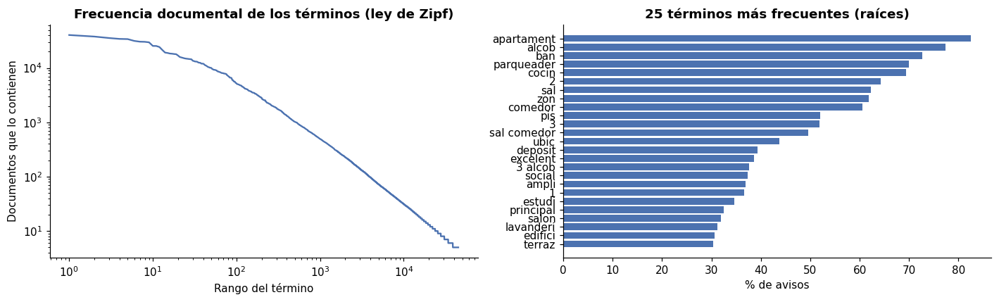

In [27]:
df_term = np.asarray((C > 0).sum(axis=0)).ravel()
orden = np.argsort(-df_term)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].loglog(np.arange(1, len(orden) + 1), np.sort(df_term)[::-1], color="#4C72B0")
axes[0].set(title="Frecuencia documental de los términos (ley de Zipf)", xlabel="Rango del término", ylabel="Documentos que lo contienen")
top = pd.Series(df_term[orden[:25]], index=vocab[orden[:25]])[::-1]
axes[1].barh(top.index, 100 * top.values / C.shape[0], color="#4C72B0")
axes[1].set(title="25 términos más frecuentes (raíces)", xlabel="% de avisos")
fig.tight_layout()
guardar(fig, "texto_vocabulario")
plt.show()

### 9.6 Vectores de documento: TF-IDF

La ponderación TF-IDF da más peso a los términos frecuentes en el documento pero raros en el corpus (Texto como datos,
Lecture 15). Con la versión de `scikit-learn` (frecuencia sublineal e IDF suavizado) y normalización L2 por documento:

$$\text{tf}_{ij} = \begin{cases} 1 + \ln c_{ij} & c_{ij} > 0 \\ 0 & c_{ij} = 0 \end{cases}, \qquad
\text{idf}_j = \ln\frac{1 + N}{1 + df_j} + 1, \qquad
x_{ij} = \frac{\text{tf}_{ij}\,\text{idf}_j}{\big\lVert \text{tf}_{i\cdot} \odot \text{idf} \big\rVert_2}$$

La clase usa $\text{tf}_{ij} = c_{ij}/\sum_{j'} c_{ij'}$ e $\text{idf}_j = \ln(N/df_j)$ (Lecture 15, lámina 18: "la idea es la
misma"); Texto como datos señala que la variante de Python "en la práctica no tiene consecuencias".

In [28]:
tfidf = TfidfTransformer(sublinear_tf=True)
X_tfidf = tfidf.fit_transform(C).tocsr()
idf = pd.Series(tfidf.idf_, index=vocab)
print("Términos con IDF más bajo (comunes):", list(idf.nsmallest(8).index))
print("Términos con IDF más alto (raros, df ≈ 5):", list(idf.nlargest(8).index))

Términos con IDF más bajo (comunes): ['apartament', 'alcob', 'ban', 'parqueader', 'cocin', '2', 'sal', 'zon']
Términos con IDF más alto (raros, df ≈ 5): ['01 ban', '01 deposit', '04', '1 70', '1 agost', '1 aument', '1 calent', '1 camil']


### 9.7 Reducción de dimensión no supervisada

LSA (análisis semántico latente). Gentzkow et al. presentan la reducción por componentes principales (sec. 3.1.2, ec. 3,
p. 544) y el LSA como su versión para matrices de texto (nota 12, p. 548); Ash y Hansen (p. 662) también lo describen. La clase
hace PCA centrada y escalada sobre conteos (`prcomp(x, scale = TRUE)`, cuaderno `02_LDA`). Aquí se aplica la SVD truncada a la
matriz TF-IDF $\mathbf{X}$ (dispersa, sin centrar):

$$\mathbf{X} \approx \mathbf{U}_K \boldsymbol{\Sigma}_K \mathbf{V}_K^{\top}, \qquad \mathbf{Z} = \mathbf{U}_K \boldsymbol{\Sigma}_K \in \mathbb{R}^{N \times K}$$

La proporción de la "energía" del texto que captura el componente $k$ es

$$\text{VE}_k = \frac{\sigma_k^2}{\lVert \mathbf{X} \rVert_F^2} = \frac{\sigma_k^2}{N}$$

(cada fila de $\mathbf{X}$ tiene norma L2 igual a 1, así que $\lVert \mathbf{X} \rVert_F^2 = N$). No hay un criterio objetivo para
$K$ (Lecture 15): se guardan 50 componentes y el número final se elige en la modelación.

Tópicos LDA (Blei, Ng y Jordan, 2003; Lecture 15, lámina 63; Gentzkow et al., ec. 4–5). Modelo generativo sobre los
conteos de unigramas:

$$\boldsymbol{\beta}_k \sim \text{Dirichlet}(\eta), \quad \boldsymbol{\theta}_i \sim \text{Dirichlet}(\alpha), \quad
z_{in} \mid \boldsymbol{\theta}_i \sim \text{Categórica}(\boldsymbol{\theta}_i), \quad
w_{in} \mid z_{in} \sim \text{Categórica}(\boldsymbol{\beta}_{z_{in}})$$

con $\alpha = \eta = 1/K$ (valores por defecto de `scikit-learn`). $\boldsymbol{\theta}_i$ es la composición de tópicos del aviso
$i$ y $\boldsymbol{\beta}_k$ la distribución de palabras del tópico $k$.

Elección de K. Gentzkow et al. (p. 549) sugieren empezar "del orden de diez" y ajustar. El cuaderno de clase elige $K$ por
factor de Bayes en otro corpus; aquí se elige con estos datos, minimizando la perplejidad fuera de muestra en un 20 % de
avisos retenidos (agrupando los duplicados de texto, para que una copia no quede en ambos lados):

$$\text{perplejidad} = \exp\left(-\frac{\sum_{i \in \text{ret}} \log p(\mathbf{w}_i)}{\sum_{i \in \text{ret}} m_i}\right)$$

donde $m_i$ es el número de palabras del aviso $i$. Ambos métodos son no supervisados (no usan el precio), así que se
ajustan con entrenamiento y prueba juntos; Gentzkow et al. (p. 555) proponen precisamente ajustar los tópicos en el corpus
grande y usarlos luego en la regresión.

Nota sobre las cifras. La perplejidad que vale es la que imprime la celda siguiente (K = 10: 327,0). La
bitácora (paso R6) registró valores de una corrida anterior a la corrección ortográfica con BETO (K = 10: 327,1); la
elección de K no cambió.

In [29]:
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.model_selection import GroupShuffleSplit

K_LSA = 50
svd = TruncatedSVD(n_components=K_LSA, random_state=SEMILLA)
Z = svd.fit_transform(X_tfidf)
VARS_LSA = [f"lsa_{k:02d}" for k in range(K_LSA)]
gdf[VARS_LSA] = Z
ve_lsa = svd.singular_values_ ** 2 / sp.linalg.norm(X_tfidf, "fro") ** 2

uni = ~es_bigrama
C_uni = C[:, uni]
vocab_uni = vocab[uni]
a_idx, b_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA).split(C_uni, groups=gdf["grupo_texto"]))
perplejidad = {}
for K in (5, 10, 15, 20, 25):
    m = LatentDirichletAllocation(n_components=K, learning_method="online", batch_size=2048, max_iter=15,
                                  random_state=SEMILLA, n_jobs=4).fit(C_uni[a_idx])
    perplejidad[K] = m.perplexity(C_uni[b_idx])
perplejidad = pd.Series(perplejidad, name="perplejidad fuera de muestra")
K_LDA = int(perplejidad.idxmin())
print(f"K elegido por perplejidad: {K_LDA}")
perplejidad.to_frame()

K elegido por perplejidad: 10


,perplejidad fuera de muestra
5,328.552
10,326.997
15,328.355
20,328.389
25,338.768


In [30]:
lda = LatentDirichletAllocation(n_components=K_LDA, learning_method="online", batch_size=2048, max_iter=15,
                                random_state=SEMILLA, n_jobs=4)
theta = lda.fit_transform(C_uni)
VARS_LDA = [f"topico_{k:02d}" for k in range(K_LDA)]
gdf[VARS_LDA] = theta

# Palabras de cada tópico: más probables (β) y más distintivas por "lift" (cuaderno 02_LDA):
# lift_kj = β_kj / p̄_j, con p̄_j = (1/n) Σ_i c_ij / m_i la proporción promedio de j entre documentos (Gentzkow et al., p. 556)
beta = lda.components_ / lda.components_.sum(axis=1, keepdims=True)
m_doc = np.asarray(C_uni.sum(axis=1)).ravel()
con = m_doc > 0
p_bar = np.asarray((sp.diags(1 / m_doc[con]) @ C_uni[con]).mean(axis=0)).ravel()
lift = beta / np.maximum(p_bar, 1e-12)
topicos = pd.DataFrame({f"Tópico {k}": [", ".join(vocab_uni[np.argsort(-beta[k])[:8]]),
                                         ", ".join(vocab_uni[np.argsort(-lift[k] * (p_bar > 1e-4))[:8]])]
                        for k in range(K_LDA)}, index=["más probables (β)", "más distintivas (lift)"]).T
guardar_tabla(topicos, "lda_topicos.csv", DIR_TEXTO)
topicos

Coincide exactamente con texto/lda_topicos.csv


,más probables (β),más distintivas (lift)
Tópico 0,"apartament, chapiner, excelent, carolin, co, r...","chapiner, baa, neces, alto, iii, pens, garanti..."
Tópico 1,"zon, salon, conjunt, apartament, alcob, ban, g...","climatiz, futbol, sender, canch, tenis, squash..."
Tópico 2,"ban, apartament, zon, alcob, social, ampli, pi...","par, lavador, luc, empotr, led, control, muebl..."
Tópico 3,"san, apartament, patrici, id, quint, houm, ven...","houm, quint, colombi, pared, ven, jos, san, mls"
Tópico 4,"sant, apartament, barb, alcob, 2, ban, parquea...","haciend, jimnez, seis, nogal, cuarent, cient, ..."
Tópico 5,"cerc, apartament, call, zon, centr, comercial,...","caden, just, palatin, carull, plaz, exit, tit, ma"
Tópico 6,"apartament, ubic, ampli, zon, excelent, espaci...","encontrars, podrs, destac, pads, graci, pagin,..."
Tópico 7,"cas, 2, ban, alcob, 3, pis, nivel, 1","nivel, may, rentabl, corrient, enchap, terren,..."
Tópico 8,"apartament, ban, alcob, 2, parqueader, sal, co...","recepcin, elctric, canon, cctv, alfombr, calde..."
Tópico 9,"fr, apartament, contactan, recib, anos, finc, ...","fr, interes, codig, instagram, dispon, antioqu..."


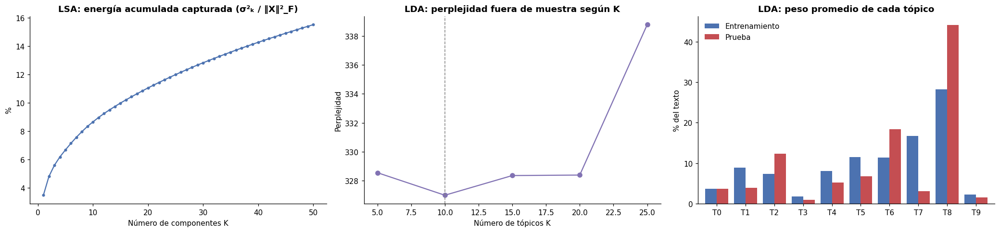

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
axes[0].plot(np.arange(1, K_LSA + 1), 100 * np.cumsum(ve_lsa), "o-", ms=3, color="#4C72B0")
axes[0].set(title="LSA: energía acumulada capturada (σ²ₖ / ‖X‖²_F)", xlabel="Número de componentes K", ylabel="%")
axes[1].plot(perplejidad.index, perplejidad.values, "o-", color="#8172B3")
axes[1].axvline(K_LDA, color="gray", ls="--", lw=1)
axes[1].set(title="LDA: perplejidad fuera de muestra según K", xlabel="Número de tópicos K", ylabel="Perplejidad")
prev = pd.DataFrame({"Entrenamiento": theta[es_tr].mean(axis=0), "Prueba": theta[~es_tr].mean(axis=0)},
                    index=[f"T{k}" for k in range(K_LDA)]) * 100
prev.plot.bar(ax=axes[2], color=[COLOR_TRAIN, COLOR_TEST], width=0.8)
axes[2].set(title="LDA: peso promedio de cada tópico", ylabel="% del texto", xlabel="")
axes[2].tick_params(axis="x", rotation=0)
axes[2].legend(frameon=False)
fig.tight_layout()
guardar(fig, "texto_lsa_lda")
plt.show()

### 9.8 ¿Qué tan informativas son las variables de texto?

Medición descriptiva (no es un modelo): correlación de Spearman $\rho$ de cada variable de texto con el precio y con el precio
por m² en entrenamiento, y diferencia estandarizada entre prueba y entrenamiento, que indica si la variable toma en
Chapinero valores poco vistos en entrenamiento:

$$d_v = \frac{\bar{v}_{\text{prueba}} - \bar{v}_{\text{entrenamiento}}}{s_{v,\text{entrenamiento}}}$$

Para el precio por m² se usa el área imputada con texto.

In [32]:
gdf["precio_m2_imp"] = (gdf["precio_mill"] / gdf["area_imp"]).where(gdf["area_imp"].between(15, 1000))
tr_t = gdf[es_tr]
VARS_TXT = VARS_DICC + VARS_NUM_TXT + ["area_imp", "banos_imp", "parqueaderos_imp"] + VARS_LDA + VARS_LSA[:10]
info = pd.DataFrame({
    "ρ precio": [spearmanr(tr_t[v], tr_t["precio_mill"], nan_policy="omit")[0] for v in VARS_TXT],
    "ρ precio/m²": [spearmanr(tr_t[v], tr_t["precio_m2_imp"], nan_policy="omit")[0] for v in VARS_TXT],
    "n entrenamiento": [int(tr_t[v].notna().sum()) for v in VARS_TXT],
    "d (prueba − entrenamiento)": [(gdf.loc[~es_tr, v].mean() - tr_t[v].mean()) / tr_t[v].std() for v in VARS_TXT],
}, index=VARS_TXT)
etiquetas_txt = {**{f"txt_{k}": f"Menciona: {k.replace('_', ' ')}" for k in list(CARACTERISTICAS) + ["para_remodelar"]},
                 "area_texto": "Área extraída del texto", "alcobas_texto": "Alcobas (texto)", "banos_texto": "Baños (texto)",
                 "parqueaderos_texto": "Parqueaderos (texto)", "piso_texto": "Piso (texto)", "estrato_texto": "Estrato (texto)",
                 "antiguedad_texto": "Antigüedad (texto)", "area_imp": "Área imputada (estructura y luego texto)",
                 "banos_imp": "Baños imputados", "parqueaderos_imp": "Parqueaderos imputados",
                 **{f"topico_{k:02d}": f"Tópico LDA {k}" for k in range(K_LDA)}, **{f"lsa_{k:02d}": f"Componente LSA {k}" for k in range(10)}}
ETIQUETAS.update(etiquetas_txt)
guardar_tabla(info.assign(nombre=info.index.map(es)), "01_texto_informatividad.csv")
info.rename(index=es).rename_axis("variable").sort_values("ρ precio", key=np.abs, ascending=False).round(3)

Difiere de stores/01_texto_informatividad.csv en las columnas ['nombre']


,ρ precio,ρ precio/m²,n entrenamiento,d (prueba − entrenamiento)
variable,,,,
Área imputada (estructura y luego texto),0.646,-0.494,20596,-0.119
Parqueaderos (texto),0.610,0.091,18506,0.063
Baños imputados,0.591,-0.158,32916,-0.140
Área extraída del texto,0.544,-0.474,11618,-0.117
Componente LSA 8,0.378,0.020,38644,0.605
Baños (texto),0.344,0.039,15228,-0.020
Componente LSA 6,0.317,-0.011,38644,0.089
Estrato (texto),0.295,0.540,2853,0.735
Alcobas (texto),0.267,-0.274,26591,-0.370


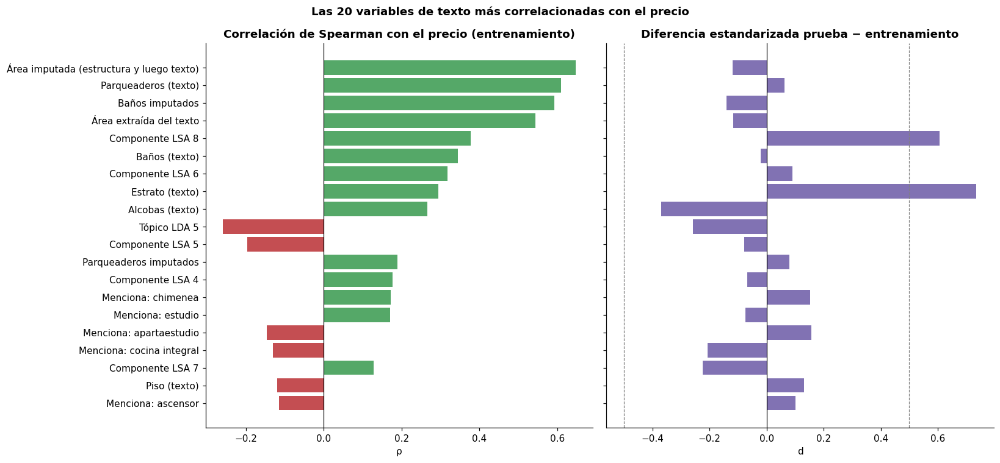

In [33]:
top = info.reindex(info["ρ precio"].abs().sort_values(ascending=False).index[:20])[::-1]
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
axes[0].barh([es(v) for v in top.index], top["ρ precio"], color=np.where(top["ρ precio"] > 0, "#55A868", "#C44E52"))
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set(title="Correlación de Spearman con el precio (entrenamiento)", xlabel="ρ")
axes[1].barh([es(v) for v in top.index], top["d (prueba − entrenamiento)"], color="#8172B3")
axes[1].axvline(0, color="black", lw=0.8)
for v in (-0.5, 0.5):
    axes[1].axvline(v, color="gray", ls="--", lw=0.8)
axes[1].set(title="Diferencia estandarizada prueba − entrenamiento", xlabel="d")
fig.suptitle("Las 20 variables de texto más correlacionadas con el precio", fontweight="bold")
fig.tight_layout()
guardar(fig, "texto_informatividad")
plt.show()

Variables de texto en el espacio (coordenadas exactas): el área recuperada del texto y la composición temática.

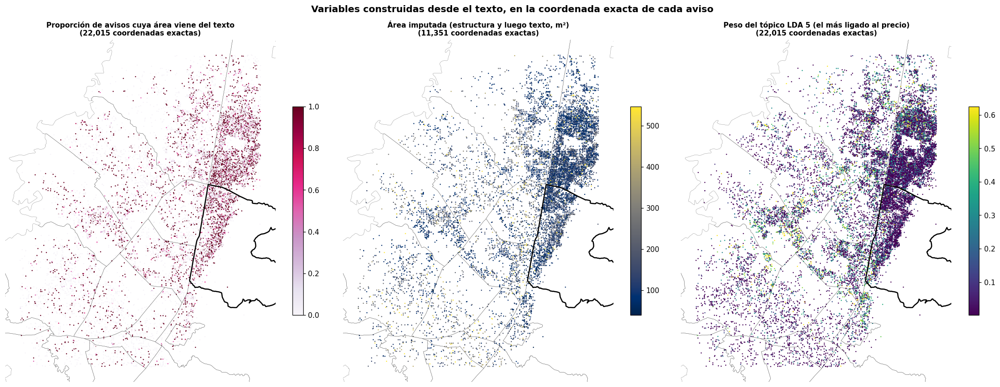

In [34]:
tmax = int(np.argmax(np.abs([spearmanr(tr_t[f"topico_{k:02d}"], tr_t["precio_mill"])[0] for k in range(K_LDA)])))
fig, axes = plt.subplots(1, 3, figsize=(20, 8))
gdf["area_desde_texto"] = (gdf["area_fuente"] == "texto").astype(float)
puntomapa(axes[0], gdf, "area_desde_texto", "Proporción de avisos cuya área viene del texto", "PuRd", robusto=False)
puntomapa(axes[1], gdf, "area_imp", "Área imputada (estructura y luego texto, m²)", "cividis")
puntomapa(axes[2], gdf, f"topico_{tmax:02d}", f"Peso del tópico LDA {tmax} (el más ligado al precio)", "viridis")
fig.suptitle("Variables construidas desde el texto, en la coordenada exacta de cada aviso", fontweight="bold", fontsize=13)
fig.tight_layout()
guardar(fig, "texto_mapas")
plt.show()

### 9.9 Guardado de la base de texto

Se guardan las variables derivadas del texto (una fila por aviso) y las matrices para la etapa de modelación:

| Archivo | Contenido |
|---|---|
| `stores/texto/texto_variables.parquet` | indicadores de diccionario, cantidades extraídas, imputaciones con su fuente, tópicos LDA, 50 componentes LSA y grupo de texto duplicado |
| `stores/texto/dtm_conteos.npz`, `tfidf.npz`, `dtm_filas.parquet`, `vocabulario.csv` | matriz documento–término $\mathbf{C}$, matriz TF-IDF $\mathbf{X}$, identificador de cada fila y vocabulario con marca de bigrama |
| `stores/texto/lda_topicos.csv`, `auditoria_correcciones.csv` | palabras de cada tópico y correcciones de letras perdidas (para auditoría manual) |

Lo que se hizo después en la modelación (usa el precio, así que debe calcularse dentro de los pliegues espaciales y agrupando
duplicados por `grupo_texto`):

1. Regresión de texto (Gentzkow et al., sec. 3.1, ec. 2, p. 543): lasso con intercepto y penalidad escalada por la
   desviación estándar de cada término,
   $\min_{\alpha, \beta} \sum_i (y_i - \alpha - x_i^{\top}\beta)^2 + n\lambda \sum_j \omega_j |\beta_j|$, con $\omega_j = \widehat{sd}(x_{\cdot j})$;
   su predicción fuera de pliegue $\hat{s}_i = \hat{\alpha} + x_i^{\top}\hat{\beta}^{(-k(i))}$ sería un puntaje de texto. Ash y
   Hansen (p. 668) advierten que en predicción el lasso suele quedarse corto frente a bosques o boosting.
2. Embeddings (Ash y Hansen; BETO en la Lecture 15), como opción si mejora la validación espacial.

Resultado (cuadernos 02 y 03). El modelo final usa como puntaje de texto un ridge de ln(precio) sobre la matriz TF-IDF
(penalidad L2 en lugar de lasso), calculado fuera de pliegue y dentro de cada pliegue de validación. Un Elastic Net con
los pesos de Gentzkow et al. se probó y no mejoró la validación. Los componentes de BETO no entraron al modelo final.

In [35]:
COLS_GUARDAR = (["property_id", "grupo_texto"] + VARS_DICC + VARS_NUM_TXT
                + ["area_imp", "area_fuente", "banos_imp", "banos_fuente", "parqueaderos_imp"] + VARS_LDA + VARS_LSA)
vocab_df = pd.DataFrame({"termino": vocab, "bigrama": es_bigrama, "df": df_term, "idf": tfidf.idf_})
if RECALCULAR:
    destino = RECALCULO / "texto"
    destino.mkdir(parents=True, exist_ok=True)
    gdf[COLS_GUARDAR].to_parquet(destino / "texto_variables.parquet", index=False)
    sp.save_npz(destino / "dtm_conteos.npz", C.tocsr())
    sp.save_npz(destino / "tfidf.npz", X_tfidf.tocsr())
    vocab_df.to_csv(destino / "vocabulario.csv", index=False)
    gdf[["property_id"]].to_parquet(destino / "dtm_filas.parquet", index=False)
    print(f"Guardado: {len(COLS_GUARDAR) - 2} variables de texto para {len(gdf):,} avisos en stores/recalculo/texto/")
else:
    # Comparación con la base de texto que usa el modelo final
    guardar_parquet(gdf[COLS_GUARDAR], "texto_variables.parquet", DIR_TEXTO)
    C_ref = sp.load_npz(DIR_TEXTO / "dtm_conteos.npz")
    print("Matriz documento término igual a la guardada:", C.shape == C_ref.shape and (C != C_ref).nnz == 0)
    X_ref = sp.load_npz(DIR_TEXTO / "tfidf.npz")
    print(f"TF-IDF: mayor diferencia con la guardada {abs(X_tfidf - X_ref).max():.2e}")
    voc_ref = pd.read_csv(DIR_TEXTO / "vocabulario.csv", dtype={"termino": str}, keep_default_na=False)
    print("Vocabulario igual al guardado:", (voc_ref["termino"].astype(str).values == vocab_df["termino"].astype(str).values).all())
    print("Orden de filas igual al guardado:",
          (pd.read_parquet(DIR_TEXTO / "dtm_filas.parquet")["property_id"].values == gdf["property_id"].values).all())

Coincide con texto_variables.parquet (93 columnas)
Matriz documento término igual a la guardada: True


TF-IDF: mayor diferencia con la guardada 0.00e+00
Vocabulario igual al guardado: True
Orden de filas igual al guardado: True


## 10. Embeddings de texto con BETO (transformer preentrenado en español)

### 10.1 ¿Por qué un embedding?

La bolsa de palabras (secciones 9.5–9.7) trata cada término como una dimensión independiente: "acabados de lujo" y
"excelentes terminados" no comparten términos y quedan lejos aunque digan lo mismo. Un embedding representa cada aviso
como un vector denso en el que textos con significado parecido quedan cerca. Ash y Hansen (2023, pp. 666–668) muestran que
las representaciones con transformers suelen superar a la bolsa de palabras en tareas de predicción, y la Lecture 15
presenta BETO como la opción para español, con dos usos: (i) congelado, como un vector de 768 dimensiones que entra a un
lasso, un bosque u otro modelo; o (ii) ajuste fino (fine-tuning), que requiere más datos etiquetados y GPU.

Aquí se usa BETO congelado (opción i): no se modifica ningún peso de la red y no se usa el precio. Es un paso de
representación no supervisado, igual que el LSA o el LDA, así que se puede calcular para entrenamiento y prueba juntos sin fuga.
El precio solo entrará en la etapa de modelación, dentro de los pliegues espaciales.

### 10.2 La red: BETO (Cañete et al., 2020)

BETO es un modelo BERT-base (Devlin et al., 2019) entrenado desde cero con ~3.000 millones de palabras en español
(`dccuchile/bert-base-spanish-wwm-uncased`): 12 capas de transformer, 12 cabezas de atención, dimensión oculta
$d = 768$, ~110 millones de parámetros y un vocabulario WordPiece de 31.002 sub-palabras. La versión uncased trabaja en
minúsculas y sin tildes, igual que nuestro texto normalizado. Se entrenó prediciendo palabras completas enmascaradas
(whole word masking).

Para un aviso tokenizado en $T$ sub-palabras, la entrada es $\mathbf{H}^{(0)} = [\mathbf{t}_1 + \mathbf{p}_1; \dots; \mathbf{t}_T + \mathbf{p}_T]$
(embedding del token más embedding de posición). Cada capa $\ell = 1, \dots, 12$ aplica autoatención multi-cabeza
(Attention Is All You Need, Vaswani et al., 2017):

$$\text{Atención}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \operatorname{softmax}\!\left(\frac{\mathbf{Q}\mathbf{K}^{\top}}{\sqrt{d_k}}\right)\mathbf{V},
\qquad \mathbf{Q} = \mathbf{H}\mathbf{W}^{Q}_h,\ \mathbf{K} = \mathbf{H}\mathbf{W}^{K}_h,\ \mathbf{V} = \mathbf{H}\mathbf{W}^{V}_h,\ d_k = 768/12 = 64$$

$$\text{MHA}(\mathbf{H}) = [\text{cabeza}_1; \dots; \text{cabeza}_{12}]\,\mathbf{W}^{O}$$

seguida de una red densa por posición, cada una con conexión residual y normalización de capa:

$$\tilde{\mathbf{H}} = \text{LayerNorm}\big(\mathbf{H}^{(\ell-1)} + \text{MHA}(\mathbf{H}^{(\ell-1)})\big), \qquad
\mathbf{H}^{(\ell)} = \text{LayerNorm}\big(\tilde{\mathbf{H}} + \text{GELU}(\tilde{\mathbf{H}}\mathbf{W}_1 + \mathbf{b}_1)\mathbf{W}_2 + \mathbf{b}_2\big)$$

La autoatención hace que el vector de cada palabra dependa de todo el aviso: "vista" en "vista a los cerros" queda
distinto de "vista" en "a la vista del parqueadero".

### 10.3 No se traduce: se restauran las tildes

BETO se entrenó en español, así que el texto no se traduce (traducir agregaría errores y perdería términos del dominio
como estrato, conjunto o los nombres de barrios). Pero su vocabulario sí tiene tildes y ñ, y nuestros avisos las
perdieron. Sin ellas, BETO parte las palabras en fragmentos y pierde significado:

| Con tilde | Tokens de BETO | Sin tilde (nuestro texto) | Tokens de BETO |
|---|---|---|---|
| balcón | `balcón` | balcon | `bal` `##con` |
| habitación | `habitación` | habitacion | `habita` `##cion` |
| baño | `baño` | bano | `ban` `##o` |
| niños | `niños` | ninos | `nin` `##os` |

Regla. Sea $\mathcal{V}$ el conjunto de palabras completas del vocabulario de BETO. Una palabra $w$ del aviso se reemplaza
por su forma con tilde $w^{*}$ solo si no hay ambigüedad:

$$w \mapsto w^{*} \quad \text{si} \quad w \notin \mathcal{V},\;\; w^{*} \in \mathcal{V},\;\; \text{sin\_tildes}(w^{*}) = w$$

Si las dos formas existen (esta/está), no se toca. Se agregan excepciones manuales para la ñ ambigua (ano(s), luego año(s)).
Esta versión del texto solo se usa para BETO.

### 10.4 Cómo se obtiene el vector de cada aviso

Se toma la última capa $\mathbf{H}^{(12)}$ y se promedian los vectores de los tokens reales (sin relleno), con la máscara de
atención $m_{it} \in \{0, 1\}$ (mean pooling):

$$\mathbf{e}_i = \frac{\sum_{t=1}^{T} m_{it}\, \mathbf{h}^{(12)}_{it}}{\sum_{t=1}^{T} m_{it}} \in \mathbb{R}^{768}$$

Se usa el promedio y no la capa pooler (el vector del token `[CLS]`) porque esa capa no viene entrenada en el modelo
publicado (los pesos `pooler.dense` faltan y se inicializarían al azar). Los textos se truncan a 256 sub-palabras; se reporta
cuántos avisos superan ese límite. El cálculo se hace en la GPU en precisión mixta (float16) y se guarda en
`stores/texto/beto_embeddings.npy` (si el archivo existe, no se recalcula).

### 10.5 Reducción de dimensión

Los 768 componentes están muy correlacionados. Se resumen con componentes principales (Lecture 15; Gentzkow et al., sec.
3.1.2), centrando $\mathbf{E}$:

$$\max_{\boldsymbol{\phi}_k} \boldsymbol{\phi}_k^{\top}\mathbf{S}\boldsymbol{\phi}_k \;\;\text{s.a.}\;\; \boldsymbol{\phi}_k^{\top}\boldsymbol{\phi}_k = 1,\ \boldsymbol{\phi}_k \perp \boldsymbol{\phi}_{1}, \dots, \boldsymbol{\phi}_{k-1},
\qquad \mathbf{S} = \tfrac{1}{N}(\mathbf{E} - \bar{\mathbf{e}})^{\top}(\mathbf{E} - \bar{\mathbf{e}})$$

Se guardan 32 componentes (`beto_pc_00` a `beto_pc_31`) y la matriz completa de 768, por si en la modelación conviene una
regresión penalizada sobre todas las dimensiones (fuera de pliegue).

Resultado en la modelación. Ni los 32 componentes de BETO congelado ni un BETO ajustado (fine-tuning, `beto_finetune.py`)
entraron al modelo final: el ajustado mejoró la zona cercana a la prueba en cerca de 1 millón, pero empeoró Chapinero
fuera en 2,6 millones (cuaderno 03, sección 6).

In [36]:
import torch
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA

MODELO_BETO = "dccuchile/bert-base-spanish-wwm-uncased"
MAX_TOKENS = 256
ruta_emb = (RECALCULO / "texto" if RECALCULAR else DIR_TEXTO) / "beto_embeddings.npy"   # sin RECALCULAR se lee el guardado
tok = AutoTokenizer.from_pretrained(MODELO_BETO)

# --- Restauración de tildes con el vocabulario de BETO (sección 10.3) ---
vocab_beto = tok.get_vocab()
acentuadas = {}
for w in sorted((w for w in vocab_beto if not w.startswith("##") and w.isalpha()), key=vocab_beto.get):
    s = sin_tildes(w)
    if s != w and s not in vocab_beto and s not in acentuadas:
        acentuadas[s] = w
acentuadas.update({"ano": "año", "anos": "años", "bano": "baño", "banos": "baños"})
texto_beto = texto.str.replace(r"\b[a-z]+\b", lambda m: acentuadas.get(m.group(0), m.group(0)), regex=True)
palabras = texto.str.split().str.len().sum()
restauradas = sum(sum(1 for w in d.split() if w in acentuadas) for d in texto)
print(f"Formas con tilde disponibles en BETO: {len(acentuadas):,} | palabras restauradas en el corpus: "
      f"{restauradas:,} ({100 * restauradas / palabras:.1f} % de las palabras)")
ejemplo = texto.str.contains(r"\bbalcon\b.*\bbano\b").values.argmax()
print("Antes: ", texto.iloc[ejemplo][:160]); print("Después:", texto_beto.iloc[ejemplo][:160])
guardar_parquet(pd.DataFrame({"property_id": gdf["property_id"].values, "texto_normalizado": texto.values,
                              "texto_beto": texto_beto.values}), "texto_normalizado.parquet", DIR_TEXTO)

frag_antes = np.mean([len(tok.tokenize(d)) / max(1, len(d.split())) for d in texto.iloc[:2000]])
frag_desp = np.mean([len(tok.tokenize(d)) / max(1, len(d.split())) for d in texto_beto.iloc[:2000]])
print(f"Sub-palabras por palabra (2.000 avisos): {frag_antes:.2f} sin tildes frente a {frag_desp:.2f} con tildes restauradas")

longitudes = np.array([len(x) for x in tok(texto_beto.tolist(), add_special_tokens=True, truncation=False)["input_ids"]])
print(f"Sub-palabras por aviso: mediana {np.median(longitudes):.0f}, p90 {np.quantile(longitudes, .9):.0f}, "
      f"máx {longitudes.max()} | avisos truncados a {MAX_TOKENS}: {100 * (longitudes > MAX_TOKENS).mean():.1f} %")

if not ruta_emb.exists():                                  # solo con RECALCULAR (GPU si existe)
    ruta_emb.parent.mkdir(parents=True, exist_ok=True)
    dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
    beto = AutoModel.from_pretrained(MODELO_BETO).to(dispositivo).eval()
    docs = texto_beto.tolist()
    orden_lon = np.argsort(longitudes)                      # lotes de longitud parecida: menos relleno, más rápido
    E = np.zeros((len(docs), beto.config.hidden_size), dtype=np.float32)
    import time as _t
    t0 = _t.time()
    with torch.inference_mode(), torch.autocast(device_type=dispositivo, dtype=torch.float16, enabled=dispositivo == "cuda"):
        for i in range(0, len(docs), 128):
            lote = orden_lon[i:i + 128]
            enc = tok([docs[j] for j in lote], padding=True, truncation=True, max_length=MAX_TOKENS,
                      return_tensors="pt").to(dispositivo)
            H = beto(**enc).last_hidden_state                                  # T × 768 por aviso
            m = enc["attention_mask"].unsqueeze(-1).to(H.dtype)
            E[lote] = ((H * m).sum(1) / m.sum(1)).float().cpu().numpy()       # mean pooling
    np.save(ruta_emb, E)
    print(f"Embeddings calculados en {_t.time() - t0:.0f} s con {dispositivo}")
E = np.load(ruta_emb)
print(f"Matriz de embeddings E: {E.shape[0]:,} × {E.shape[1]}")

Formas con tilde disponibles en BETO: 3,015 | palabras restauradas en el corpus: 280,858 (8.0 % de las palabras)


Antes:  apartamento en bogota chico navarra apartamento remodelado diez 10 anos de construido ubicado a escasos pasos del parque dispone de tres 3 alcoba estudio sala c
Después: apartamento en bogotá chico navarra apartamento remodelado diez 10 años de construido ubicado a escasos pasos del parque dispone de tres 3 alcoba estudio sala c
Coincide con texto_normalizado.parquet (3 columnas)


Sub-palabras por palabra (2.000 avisos): 1.26 sin tildes frente a 1.17 con tildes restauradas


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (678 > 512). Running this sequence through the model will result in indexing errors


Sub-palabras por aviso: mediana 78, p90 138, máx 695 | avisos truncados a 256: 0.4 %
Matriz de embeddings E: 48,930 × 768


In [37]:
pca_beto = PCA(n_components=32, random_state=SEMILLA)
P = pca_beto.fit_transform(E)
VARS_BETO = [f"beto_pc_{k:02d}" for k in range(32)]
gdf[VARS_BETO] = P
guardar_parquet(pd.concat([gdf[["property_id"]], gdf[VARS_BETO]], axis=1), "beto_componentes.parquet", DIR_TEXTO)

# Ilustración: los avisos más parecidos (coseno) a uno de Chapinero que menciona "vista"
En = E / np.linalg.norm(E, axis=1, keepdims=True)
consulta = np.where((~es_tr) & texto.str.contains("vista").values)[0][0]
sim = En @ En[consulta]
sim[gdf["grupo_texto"].values == gdf["grupo_texto"].values[consulta]] = -1      # sin sus duplicados
top = np.argsort(-sim)[:4]
print("Aviso de consulta:", texto_beto.iloc[consulta][:200], "\n")
pd.DataFrame({"similitud coseno": sim[top].round(3), "muestra": gdf["muestra"].values[top],
              "texto (inicio)": texto_beto.iloc[top].str[:150].values})

Coincide con beto_componentes.parquet (33 columnas)
Aviso de consulta: apartamento en en bogotá la cabrera cod vrei 16819 inf flor jimnez remodele doscientos cincuenta m2 en el mejor barrio de bogotá piso alto espectacular vista de 180 edificio super exclusivo y tradicio 



,similitud coseno,muestra,texto (inicio)
0,0.982,test,apartamento en en bogotá la cabrera cod vrei 1...
1,0.973,test,apartamento en en bogotá la cabrera cod vrei 2...
2,0.951,test,apartamento en en bogotá inf flor jiménez remo...
3,0.951,train,apartamento en en bogotá castilla kennedy cod ...


Coincide exactamente con stores/01_beto_informatividad.csv


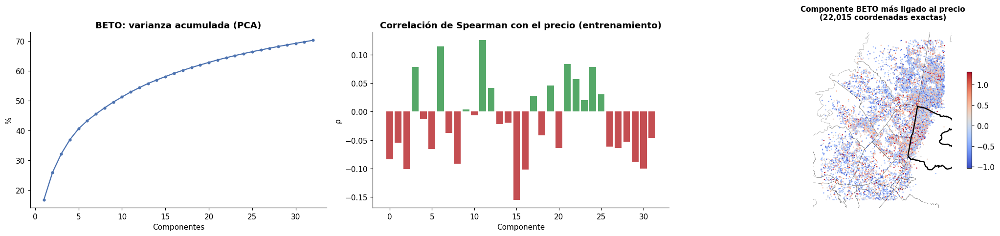

,% varianza,ρ precio,ρ precio/m²,d (prueba − entrenamiento)
beto_pc_15,1.078,-0.155,0.006,0.183
beto_pc_11,1.458,0.125,-0.061,-0.093
beto_pc_06,2.233,0.114,-0.116,-0.188
beto_pc_16,0.995,-0.102,-0.011,0.110
beto_pc_02,6.207,-0.101,-0.093,-0.168
beto_pc_30,0.511,-0.100,-0.071,-0.047
beto_pc_08,1.921,-0.092,0.067,0.064
beto_pc_29,0.527,-0.088,-0.023,0.168
beto_pc_21,0.747,0.084,0.034,-0.027
beto_pc_00,16.759,-0.083,-0.155,-0.178


In [38]:
info_beto = pd.DataFrame({
    "% varianza": 100 * pca_beto.explained_variance_ratio_,
    "ρ precio": [spearmanr(P[es_tr, k], gdf.loc[es_tr, "precio_mill"])[0] for k in range(32)],
    "ρ precio/m²": [spearmanr(P[es_tr, k], gdf.loc[es_tr, "precio_m2_imp"], nan_policy="omit")[0] for k in range(32)],
    "d (prueba − entrenamiento)": (P[~es_tr].mean(0) - P[es_tr].mean(0)) / P[es_tr].std(0),
}, index=VARS_BETO)
guardar_tabla(info_beto.assign(nombre=[f"Componente BETO {k}" for k in range(32)]), "01_beto_informatividad.csv")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
axes[0].plot(np.arange(1, 33), np.cumsum(info_beto["% varianza"]), "o-", ms=3, color="#4C72B0")
axes[0].set(title="BETO: varianza acumulada (PCA)", xlabel="Componentes", ylabel="%")
axes[1].bar(np.arange(32), info_beto["ρ precio"], color=np.where(info_beto["ρ precio"] > 0, "#55A868", "#C44E52"))
axes[1].set(title="Correlación de Spearman con el precio (entrenamiento)", xlabel="Componente", ylabel="ρ")
gdf["beto_pc_mas_ligado"] = P[:, int(np.argmax(np.abs(info_beto["ρ precio"].values)))]
puntomapa(axes[2], gdf, "beto_pc_mas_ligado", "Componente BETO más ligado al precio", "coolwarm")
fig.tight_layout()
guardar(fig, "texto_beto")
plt.show()
info_beto.sort_values("ρ precio", key=np.abs, ascending=False).head(10).round(3)